# M05a · Dérivées, Taylor et calcul numérique — solutions (notebook exécuté)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cemah2/workbookMaths/blob/main/chapitres/m05a_derivees_taylor/05_solutions.ipynb)

Les réponses des exercices, exécutées. Les démarches détaillées (le *pourquoi*, les erreurs fréquentes, les variantes) sont dans `05_solutions.md`. Les cellules marquées `answer` enregistrent les réponses vérifiées par `wbm.check` (`tools/build_answers.py`).

| Partie | ID | Titre | Type | ★ | ⏱️ |
|---|---|---|---|---|---|
| 0 | M05a.1 à M05a.10, M05a.14 | Les exercices papier (vérification) | ✏️ 🔗 | | |
| A | M05a.18 | Évaluer un polynôme de Taylor · `taylor_polynomial` | 🔨 | ★ | 20 |
|  | M05a.19 | La méthode de Newton, avec ses cas d'échec · `newton` | 🔨 | ★ | 20 |
|  | M05a.20 | L'extrapolation de Richardson : annuler le terme d'erreur en h² · `richardson_derivative` | 🔨 | ★★ | 20 |
|  | M05a.21 | L'epsilon machine, en float64, float32 et float16 · `machine_epsilon` | 🔨 | ★ | 15 |
|  | M05a.22 | Un log-sum-exp stable · `logsumexp` | 🔨 | ★ | 15 |
|  | M05a.23 | SymPy `series` et `numpy.finfo` contre tes fonctions | 📦 | ★ | 15 |
| B | M05a.24 | Prédire : Newton depuis un mauvais point de départ | 🔮 | ★ | 10 |
|  | M05a.25 | Taylor de plus en plus loin : où le polynôme décroche | 🔬 | ★★ | 20 |
|  | M05a.26 | Une fonction et ses polynômes de Taylor d'ordre 1, 2 et 3 | 🎨 | ★ | 20 |
| C | M05a.27 | Chasse à l'erreur : une softmax qui renvoie `nan` | 🐛 | ★ | 15 |
|  | M05a.28 | Erreur relative ou absolue : choisir la tolérance d'un test | 🛠️ | ★ | 10 |
|  | M05a.29 | Défi : une racine cubique à 10⁻¹² en le moins d'itérations possible | 🏆 | ★★★ | 25 |

In [1]:
# ⚙️ SETUP: run this cell first (on Colab or on your computer)
FAST_MODE = True  # True = quick version (a few seconds per cell); False = bigger experiments
SEED = 42

import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/cemah2/workbookMaths.git"
DRIVE_DIR = Path("/content/drive/MyDrive/workbookMaths")

try:
    import google.colab  # noqa: F401  (this module only exists on Colab)
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    subprocess.run(["git", "config", "--global", "--add", "safe.directory", str(DRIVE_DIR)])
    if not (DRIVE_DIR / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(DRIVE_DIR)], check=True)
    else:
        # Get the new chapters. Your own work only lives in mon_travail/, which Claude never
        # touches, so "rebase + autostash" keeps it safe (even with local commits).
        identity = subprocess.run(["git", "-C", str(DRIVE_DIR), "config", "user.email"],
                                  capture_output=True).returncode == 0
        who = [] if identity else ["-c", "user.name=Workbook", "-c", "user.email=workbook@localhost"]
        pull = subprocess.run(["git", *who, "-C", str(DRIVE_DIR), "pull", "--rebase", "--autostash"],
                              capture_output=True, text=True)
        conflicts = subprocess.run(["git", "-C", str(DRIVE_DIR), "diff", "--name-only", "--diff-filter=U"],
                                   capture_output=True, text=True).stdout.split()
        if conflicts:  # a file changed outside mon_travail/ AND by Claude: git leaves conflict markers in it
            print("⚠️ Tes modifications de " + ", ".join(conflicts) + " (hors de mon_travail/) entrent en conflit "
                  "avec la nouvelle version ; elles sont gardées dans `git stash`. Pour reprendre la version du "
                  "dépôt : git restore --source=HEAD --staged --worktree <fichier> (00_setup/COLAB.md, « Problèmes "
                  "fréquents »).")
        elif pull.returncode != 0:
            print("⚠️ git pull a échoué (voir 00_setup/COLAB.md, « Problèmes fréquents ») :\n" + pull.stderr)
    ROOT = DRIVE_DIR
else:
    ROOT = Path(os.environ.get("WBM_ROOT", Path.cwd())).resolve()
    while not (ROOT / "src" / "wbm").exists() and ROOT != ROOT.parent:
        ROOT = ROOT.parent
    if not (ROOT / "src" / "wbm").exists():
        raise FileNotFoundError("Dépôt introuvable : ouvre ce notebook depuis le dossier de workbookMaths.")

os.environ["WBM_ROOT"] = str(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import wbm  # noqa: E402

cfg = wbm.setup(seed=SEED, fast=FAST_MODE)
FAST_MODE = cfg.fast
mymath = wbm.load_mymath("ref")  # reference implementation

🧪 workbookMaths : environnement
   Plateforme : Local (Linux x86_64, 2 CPU)
   Python 3.13.18 | numpy 2.1.3 | scipy 1.16.3 | sympy 1.14.0 | matplotlib 3.10.0 | pandas 2.2.3 | scikit-learn 1.6.1
   Graine : 42 | FAST_MODE : True


## Objectifs et rappel express

- Vérifier tes calculs papier (partie 0) : dérivée seconde et convexité, extrema, polynômes de Taylor et reste, méthode de Newton, erreur des différences finies, flottants, meilleur pas, log-sum-exp.
- Écrire les cinq fonctions de `mymath/approx.py` et les tester, puis utiliser SymPy et `numpy.finfo`.
- Prédire Newton depuis un mauvais départ, voir une série de Taylor décrocher, tracer des polynômes de Taylor, chasser les erreurs d'une softmax, comparer des flottants, calculer une racine cubique en quelques pas.

**Rappel express.** $f'' \ge 0$ : convexe ; $P_n(x) = \sum_{k=0}^{n} \frac{f^{(k)}(a)}{k!}(x - a)^k$, reste $\le \frac{M}{(n+1)!}|x - a|^{n+1}$ ; Newton : $x_{k+1} = x_k - \frac{f(x_k)}{f'(x_k)}$ ; différence avant : erreur $\approx \frac{h}{2}f''$, centrée : $\approx \frac{h^2}{6}f'''$, Richardson : $\frac{4D(h/2) - D(h)}{3}$ ; `float64` : $\varepsilon = 2^{-52}$ ; $\text{LSE}(\mathbf{v}) = m + \ln\sum_i e^{v_i - m}$, $m = \max_i v_i$, entre $m$ et $m + \ln n$.

## Partie 0 · Vérifier tes exercices papier (✏️ M05a.1 à M05a.10, 🔗 M05a.14)

Fais d'abord les exercices de `02_exercices.md` **sur papier**, dans ta copie de `06_mes_reponses.md`. Reporte ensuite chaque réponse ici : **la valeur** que tu as trouvée, sous la forme indiquée en commentaire, jamais le calcul qui y mène :
- un entier, ou un nombre avec un point décimal, `-1.25`, arrondi comme le demande la question ;
- une fraction irréductible entre guillemets, `"7/9"` ; une expression en $x$ entre guillemets, `"2*x**3 - x"` ;
- une liste `[-1.5, 2.5]`, un intervalle entre guillemets `"[-4, 6]"`, `True` / `False`, une lettre entre guillemets, `"B"`, ou un texte entre guillemets, `"10.01"`.

Les réponses pas encore remplies affichent ⏳.

In [2]:
# Part 0: the answers are computed exactly from the statements
import math
from fractions import Fraction

**Ex M05a.1 — Dérivées secondes et convexité**

In [3]:
wbm.record("M05a.1a", 4, mistakes={"c'est f'(0) ; dérive encore une fois": 1, "la dérivée de e^(2x) est 2 e^(2x) : n'oublie pas le facteur 2 de la règle de la chaîne": 2})
wbm.record("M05a.1b", "[-1 ; 1]", kind="interval", mistakes={"l'intervalle demandé est fermé : g est concave aussi à ses bornes": "]-1 ; 1[", "g est concave là où g'' est négative ou nulle, pas là où elle est positive": "]-oo ; -1] U [1 ; +oo["})
wbm.record("M05a.1c", [-1, 1])
wbm.record("M05a.1d", 6 * math.e, decimals=4, mistakes={"c'est w'(1) ; dérive encore une fois, par la règle du produit": 2 * math.e, "w'(x) = 2x e^(x²) est un produit : sa dérivée a deux termes": 4 * math.e})
wbm.record("M05a.1e", False, mistakes={"calcule la dérivée seconde de 1/(1 + x²) et étudie son signe, par exemple en 0": True})
wbm.record("M05a.1f", 1 / 2, decimals=1, mistakes={"c'est h'(2) = ln 2 + 1 ; dérive encore une fois": 1.0 + 0.6931471806})
wbm.record("M05a.1g", -6, mistakes={"un point d'inflexion annule la dérivée seconde, pas la dérivée première": -3, "la dérivée seconde de k x² est 2k": -12})
wbm.record("M05a.1h", (1 + math.e ** 2) / 2 - math.e, decimals=4, mistakes={"l'écart demandé est le milieu de la corde moins la courbe : son signe compte": math.e - (1 + math.e ** 2) / 2})

WBM_ANSWER {"hash": "cedd4c843e5de7368c99fb82b8eba4eaa52e1011ab8294acd11c0b472d915d17", "id": "M05a.1a", "kind": "int", "magnitude": 0, "mistakes": {"6491767f3008a303fcdb65d8b5df6ab45f848e1ba2f4971e476d1dac95e7e85c": "c'est f'(0) ; dérive encore une fois", "d6942664efb7168360ab039731b5d53983e7858826fd63e8e8d53e7a79ddc3a5": "la dérivée de e^(2x) est 2 e^(2x) : n'oublie pas le facteur 2 de la règle de la chaîne"}, "sign": 1}
📝 Ex M05a.1a : réponse enregistrée (int).
WBM_ANSWER {"hash": "255143e76984d62414dee80f0d52d88fa097c8ac87cf3df686b6d41d101f07a7", "id": "M05a.1b", "kind": "interval", "mistakes": {"393148580726314e377eee5289ef26f9f37130948d7b2d7fe31aa429597f5698": "l'intervalle demandé est fermé : g est concave aussi à ses bornes", "74265f33a89a5570e6471c3fcb610e549c3673510eff80f2ece7f6a3a3f3da03": "g est concave là où g'' est négative ou nulle, pas là où elle est positive"}}
📝 Ex M05a.1b : réponse enregistrée (interval).
WBM_ANSWER {"decimals": 0, "element_hashes": ["e25f5d26d4f2fdb

**Ex M05a.2 — Extrema locaux et globaux sur un intervalle fermé**

In [4]:
wbm.record("M05a.2a", [-1, 0, 2], mistakes={"f'(x) = 12x³ − 12x² − 24x se factorise par 12x : x = 0 est aussi un point critique": [-1, 2]})
wbm.record("M05a.2b", [0, 5, -27])
wbm.record("M05a.2c", 0, mistakes={"un maximum local a f'' < 0 : calcule f'' en chaque point critique": {-1, 2}})
wbm.record("M05a.2d", 37, mistakes={"compare toutes les valeurs : les points critiques et les deux bords": {32, 5}})
wbm.record("M05a.2e", -2, mistakes={"compare toutes les valeurs : les points critiques et les deux bords": {3, 0}})
wbm.record("M05a.2f", -27, mistakes={"compare les deux minimums locaux, et les bords": {0, 32}})
wbm.record("M05a.2g", 3 * 1.5 ** 4 + 4 * 1.5 ** 3 - 12 * 1.5 ** 2 + 5, decimals=4, mistakes={"compare aussi avec les bords de [−1,5 ; 1,5]": 5})
wbm.record("M05a.2h", False, mistakes={"quand x tend vers ±∞, le terme 3x⁴ l'emporte : f n'est pas bornée": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["14e5b1dae11ad31a3b12e672bd07bd907e10ba29bd8731f137c21b59815ebcc0", "a9ee6502b262876d386dae764fcdf28d3bed5526cecbc81973aab52fb37e261e", "5db97abe0d56a1e4b05bd027cea683f08dfaa1945521c0d197367cb0ebdcd190"], "hash": "aaad61f952ff2ea3519c2ffcaac3e13f6772ed7539ef8abb66804919ba56fa80", "id": "M05a.2a", "integer": true, "kind": "array", "mistakes": {"91b71cb747c0e1d9fc5e51242774e881a43ecd942347f5e73247656c1d860cf2": "f'(x) = 12x³ − 12x² − 24x se factorise par 12x : x = 0 est aussi un point critique"}, "shape": [3]}
📝 Ex M05a.2a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"decimals": 0, "element_hashes": ["746d2a4254134d8723e24f662f927fe0cdb444aae97c44ebe1b268df2fa81ba0", "01c9d061b9e6c2e86f6b69eeea0362fa9f4c8d6e0c94af2a1c9d31ec65825759", "7c4cce959af8ba058b2f37f54fd803722b8b98dda3f787f41ba4f2180209ad93"], "hash": "4faa159872a463e4d58ec9c68449cb62d974a7e67e53876d1ea808bee9f7a639", "id": "M05a.2b", "integer": true, "kind": "array", "shape

**Ex M05a.3 — Points d'inflexion et test de la dérivée seconde**

In [5]:
wbm.record("M05a.3a", [0, 4], mistakes={"p'(x) = 5x⁴ − 20x³ = 5x³(x − 4) : x = 0 est aussi un point critique": [4]})
wbm.record("M05a.3b", 320, mistakes={"c'est p'(4) ; dérive encore une fois": 0})
wbm.record("M05a.3c", 0)
wbm.record("M05a.3d", "A", mistakes={"p''(0) = 0 ne permet pas de conclure : étudie le signe de p' juste avant et juste après 0": "C", "regarde le signe de p' juste avant et juste après 0 : p croît, puis décroît ?": "B"})
wbm.record("M05a.3e", [3], mistakes={"p''(x) = 20x²(x − 3) s'annule en 0 sans changer de signe (x² ≥ 0)": [0, 3]})
wbm.record("M05a.3f", -162)
wbm.record("M05a.3g", False, mistakes={"(x⁴)'' = 12x² s'annule en 0 mais ne change pas de signe": True})

WBM_ANSWER {"decimals": 0, "element_hashes": ["363f9d60ecb13eee644cd825f11e6e24253b59c1ff213a4d3f211133e19b0f19", "659cf685d6cc26b61936f0e700e53d83b0b314813289959e18ae85f63d2e4352"], "hash": "61a4b403824ebb9e9d581ecf6d0e65473345e2b70b42f6267a470af180d26198", "id": "M05a.3a", "integer": true, "kind": "array", "mistakes": {"cf597634cbb15dfca25d57dfeb813a9e7b41df25147b97573325c15fe7bb1487": "p'(x) = 5x⁴ − 20x³ = 5x³(x − 4) : x = 0 est aussi un point critique"}, "shape": [2]}
📝 Ex M05a.3a : réponse enregistrée (array, 0 décimale).
WBM_ANSWER {"hash": "16c890e4d4a5c1c63b1d2f667e1088755dd612219809b4a4435c7169ec089dc0", "id": "M05a.3b", "kind": "int", "magnitude": 2, "mistakes": {"f248f97eec09a8e906e88d0db1df1ddb3eff85b0a7bb9a754e4cd9e5dc145762": "c'est p'(4) ; dérive encore une fois"}, "sign": 1}
📝 Ex M05a.3b : réponse enregistrée (int).
WBM_ANSWER {"hash": "a892768b0e697ec932d7673c6073bec2e6d1a874bc1ef393e4efc045dc2a4e7b", "id": "M05a.3c", "kind": "int", "magnitude": null, "sign": 0}
📝 Ex M

**Ex M05a.4 — Polynômes de Taylor de trois fonctions usuelles**

In [6]:
wbm.record("M05a.4a", "1 - x**2/2", kind="expr", variables=("x",), mistakes={"cos''(0) = −cos 0 = −1 : le terme d'ordre 2 est négatif": "1 + x**2/2", "divise le terme d'ordre 2 par 2! = 2": "1 - x**2"})
wbm.record("M05a.4b", "x - x**2/2 + x**3/3", kind="expr", variables=("x",), mistakes={"la dérivée troisième de ln(1 + x) en 0 vaut 2, et 2/3! = 1/3": "x - x**2/2 + x**3/6", "les signes alternent": "x + x**2/2 + x**3/3"})
wbm.record("M05a.4c", "1 + x + x**2 + x**3", kind="expr", variables=("x",), mistakes={"la dérivée k-ième de 1/(1 − x) en 0 vaut k! : chaque coefficient f⁽ᵏ⁾(0)/k! vaut 1": "1 + x + x**2/2 + x**3/6", "dérive 1/(1 − x) avec la règle de la chaîne : (1 − x)′ = −1": "1 - x + x**2 - x**3"})
wbm.record("M05a.4d", math.e * (1 + 0.1 + 0.1 ** 2 / 2), decimals=4, mistakes={"le polynôme est centré en a = 1 : les puissances sont celles de (x − 1)": 1 + 1.1 + 1.1 ** 2 / 2, "en a = 1, les dérivées de eˣ valent e, pas 1": 1 + 0.1 + 0.1 ** 2 / 2})
wbm.record("M05a.4e", 0.1 - 0.1 ** 2 / 2 + 0.1 ** 3 / 3, decimals=5, mistakes={"le coefficient de x³ est 1/3": 0.1 - 0.1 ** 2 / 2 + 0.1 ** 3 / 6})
wbm.record("M05a.4f", Fraction(1, 24), kind="fraction", simplified=True, mistakes={"cos⁽⁴⁾(0) = cos 0 = 1 : le terme est positif": "-1/24", "divise par 4!, et non par 4": "1/4", "4! = 4 × 3 × 2 × 1": "1/12"})
wbm.record("M05a.4g", 1 - 0.3 ** 2 / 2, decimals=3, mistakes={"sin′(π/2) = cos(π/2) = 0 : pas de terme d'ordre 1": 1.3 - 0.3 ** 2 / 2, "divise le terme d'ordre 2 par 2! = 2": 1 - 0.3 ** 2})
wbm.record("M05a.4h", 1, mistakes={"le coefficient de (x − 1)² est q''(1)/2!": 2})

WBM_ANSWER {"hash": "c484acc4772a9d3c9f429f3c32fa87239377d757d9c8dca4ac436b5ffb34cf0d", "id": "M05a.4a", "kind": "expr", "mistakes": {"53ed4480da077e3c670457656095a4b8ed8bcb14e457585b2f68bb293b1a00e1": "divise le terme d'ordre 2 par 2! = 2", "c82e07762ba94a63e300d55a51edaef98c63d0a5b9b6b9217cb7d5ac7c11359c": "cos''(0) = −cos 0 = −1 : le terme d'ordre 2 est négatif"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}


📝 Ex M05a.4a : réponse enregistrée (expr).
WBM_ANSWER {"hash": "a665659b1f51e3d1407736a2da852d868ad1a8229ffbb24fbf1e044db5e7a873", "id": "M05a.4b", "kind": "expr", "mistakes": {"9ba3cd8a7c86cf74cb7b71508f09fb17dbec7efc0ee651a1f2113f8f3a08459a": "les signes alternent", "f14cf1a4d474699163a2245b83189252afb615733cd76ef8ef684c1b02144460": "la dérivée troisième de ln(1 + x) en 0 vaut 2, et 2/3! = 1/3"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]], "variables": ["x"]}
📝 Ex M05a.4b : réponse enregistrée (expr).
WBM_ANSWER {"hash": "2444506e0184964f33b70145be22595623f6bdb0ad446e63fbc542b94553fb4c", "id": "M05a.4c", "kind": "expr", "mistakes": {"0c8d6b6fc89931993ae5e6b29507f8b4b304382c32681486af2a2f987718460b": "la dérivée k-ième de 1/(1 − x) en 0 vaut k! : chaque coefficient f⁽ᵏ⁾(0)/k! vaut 1", "f32dfcce188254eebdc921603699949e5e515a30e466751b7cb73d0dcadee520": "dérive 1/(1 − x) avec la règle de la chaîne : (1 − x)′ = −1"}, "points": [["1/3"], ["5/7"], ["6/5"], ["-2/5"], ["9/4"]]

**Ex M05a.5 — Le reste de Taylor : borner l'erreur d'une approximation**

In [7]:
wbm.record("M05a.5a", 0.5 - 0.5 ** 3 / 6, decimals=6, mistakes={"l'ordre 3 contient le terme en x³, divisé par 3! = 6": 0.5 - 0.5 ** 3 / 3})
wbm.record("M05a.5b", abs(math.sin(0.5) - (0.5 - 0.5 ** 3 / 6)), decimals=7)
wbm.record("M05a.5c", 0.5 ** 5 / 120, decimals=7, mistakes={"le reste d'ordre 4 utilise la dérivée cinquième, avec x⁵/5!": 0.5 ** 4 / 24})
wbm.record("M05a.5d", 9, mistakes={"l'ordre n donne le reste avec (n + 1)! : n est un de moins que le nombre dont tu prends la factorielle": 10})
wbm.record("M05a.5e", 2 * 0.1 ** 3 / 6, decimals=6, mistakes={"le reste d'ordre 2 divise par 3! = 6": 2 * 0.1 ** 3 / 2})
wbm.record("M05a.5f", 0.2 ** 4 / 24, decimals=7, mistakes={"le terme en x³ de cos est nul : P₂ = P₃, et le reste d'ordre 3 utilise x⁴/4!": 0.2 ** 3 / 6})
wbm.record("M05a.5g", 0.006 ** (1 / 3), decimals=4, mistakes={"x³/6 < 0,001 donne x³ < 0,006 : prends la racine cubique": 0.006 ** (1 / 2)})

WBM_ANSWER {"coarse_any": {"1": ["4672f07af7510fc07163d850429b885605ea7f5c1854300863abab229ef053eb"]}, "coarser": {"2": ["f574a713550521edc6c4072116d7b95b32c2183d16ba97ea299326e973aa8e9a"], "3": ["0f3fab5e9e755a7ba88afb234e9534ec15f3cc40ca2797c2e7015f3d45367d6d"], "4": ["dd573e858864cf829054bf8356a88a3f98a241e2b963acda78bef8aaa66da9b5"]}, "decimals": 6, "hash": "a25b4c5bcc6f5548d0edf0fb3e3077b840c1ba6758b2a1dcdfadc66d4e2478e3", "hash_coarse": "569c2f63157ad5e4846b2ef70cefff9e7e22d7e18f8d44e5fbce8bbf04199317", "id": "M05a.5a", "kind": "float", "magnitude": -1, "mistakes": {"3c1966a10b90e01a6f83a6bd8558936b3707c642ead48e3692d4b2be72e967af": "l'ordre 3 contient le terme en x³, divisé par 3! = 6"}, "sign": 1}
📝 Ex M05a.5a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"4": ["7129a0d40b76613eae67c9f5da9fc1dc9ff91cfb000701a73c87cf28b7d54428"]}, "coarser": {"5": ["b4a4f105cdd94bd4619c414b24ed31a067e341fc50f8720d16e330db483157c7"]}, "decimals": 7, "hash": "316de0257cd83

**Ex M05a.6 — Newton à la main : une racine carrée en trois pas**

In [8]:
wbm.record("M05a.6a", Fraction(19, 6), kind="fraction", simplified=True, mistakes={"x₁ = x₀ − f(x₀)/f′(x₀) avec f(3) = −1 : le pas va vers la droite": "17/6"})
wbm.record("M05a.6b", Fraction(721, 228), kind="fraction", simplified=True, mistakes={"x₂ part de x₁, avec f′(x₁) = 2x₁": "361/114"})
wbm.record("M05a.6c", float((Fraction(721, 228) + 10 / Fraction(721, 228)) / 2), decimals=10, mistakes={"c'est x₂ ; fais encore un pas": 721 / 228})
wbm.record("M05a.6d", (721 / 228 - math.sqrt(10)) * 1e6, decimals=2, mistakes={"l'erreur demandée est x₂ − √10 : x₂ est au-dessus de √10": -(721 / 228 - math.sqrt(10)) * 1e6})
wbm.record("M05a.6e", (721 / 228 - math.sqrt(10)) / (19 / 6 - math.sqrt(10)) ** 2, decimals=3, mistakes={"le dénominateur est le carré de l'erreur de x₁": (721 / 228 - math.sqrt(10)) / (19 / 6 - math.sqrt(10))})
wbm.record("M05a.6f", -math.sqrt(10), decimals=4, mistakes={"depuis un point négatif, la suite reste négative : elle va vers l'autre racine": math.sqrt(10)})
wbm.record("M05a.6g", False, mistakes={"en 0, f′(0) = 0 : la tangente est horizontale et ne coupe pas l'axe": True})
wbm.record("M05a.6h", 4 - 2 * math.log(2), decimals=4, mistakes={"le pas est g(x₀)/g′(x₀) avec g′(2) = 1/2 : diviser par 1/2, c'est multiplier par 2": 2 - (math.log(2) - 1) / 2, "x₁ = x₀ − g(x₀)/g′(x₀) : vérifie le signe": 2 * math.log(2)})

WBM_ANSWER {"hash": "3ed01d25096a2b613b35e724a769574eb176163031fc19302b9af66e14fccdd8", "id": "M05a.6a", "kind": "fraction", "mistakes": {"01ab4d42e7bfb8d90f08dc31fbd3735a58b67bb3eda307dc332a18e77740d09e": "x₁ = x₀ − f(x₀)/f′(x₀) avec f(3) = −1 : le pas va vers la droite"}, "sign": 1, "simplified": true}
📝 Ex M05a.6a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "8023544270f1acbe5f6031cac1ad2c6daa4a961b8280e013f7e96f656863cc18", "id": "M05a.6b", "kind": "fraction", "mistakes": {"cef48d6f642d2649beaf57a3c469db0a092952505c5e8efe97eb3ff975f53d1b": "x₂ part de x₁, avec f′(x₁) = 2x₁"}, "sign": 1, "simplified": true}
📝 Ex M05a.6b : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"0": ["f36606f88035b05d91942abf58c8a50e50419aec368f861ed198fa4096fbaf45"]}, "coarser": {"1": ["2501e4317cac08730a27c3333d30038531dd49db93261f7432302a7ef3690b6f"], "2": ["9f4100e08ae2833065dd7c4bdb6a156db9c3a35c8417a1c1e2411772e9517ee2"], "3": ["49af55cd0359af462354be815694a99e71d4d2f3733a99f57efcbb

**Ex M05a.7 — L'erreur d'une différence avant et d'une différence centrée, par Taylor**

In [9]:
wbm.record("M05a.7a", Fraction(1, 4), kind="fraction", simplified=True, mistakes={"(√x)′ = 1/(2√x)": "1/2"})
wbm.record("M05a.7b", (math.sqrt(4.2) - 2) / 0.2, decimals=5, mistakes={"divise la différence des deux valeurs par h": math.sqrt(4.2) - 2})
wbm.record("M05a.7c", (math.sqrt(4.2) - 2) / 0.2 - 0.25, decimals=5, mistakes={"l'erreur est la différence avant moins f′(4) : son signe compte": 0.25 - (math.sqrt(4.2) - 2) / 0.2})
wbm.record("M05a.7d", 0.1 * (-1 / 32), decimals=6, mistakes={"f″(x) = −1/(4 x^(3/2)) est négative": 0.1 / 32, "la prévision est (h/2) f″(4), avec h/2 = 0,1": 0.2 * (-1 / 32)})
wbm.record("M05a.7e", (math.sqrt(4.2) - math.sqrt(3.8)) / 0.4, decimals=6, mistakes={"la différence centrée divise par 2h, l'écart entre les deux points": (math.sqrt(4.2) - math.sqrt(3.8)) / 0.2})
wbm.record("M05a.7f", Fraction(1, 12800), kind="fraction", simplified=True, mistakes={"f‴(x) = 3/(8 x^(5/2)) est positive": "-1/12800", "h² = 0,04 se divise par 6, et f‴(4) = 3/256": "1/2133"})
wbm.record("M05a.7g", 4, mistakes={"l'erreur de la différence centrée est proportionnelle à h²": 2})
wbm.record("M05a.7h", (math.sqrt(4.2) - 4 + math.sqrt(3.8)) / 0.04, decimals=5, mistakes={"la question demande la différence seconde, calculée avec les trois valeurs, pas f″(4)": -1 / 32})

WBM_ANSWER {"hash": "b95a67e0a4b4fa7e39d850c4bca0c1d944dd08d29c14f5e4ecb850a19a4af68a", "id": "M05a.7a", "kind": "fraction", "mistakes": {"94568328fc0eb98b0ac68d3304a9a4b2f24776c192105c5e77c7b026a6d410d4": "(√x)′ = 1/(2√x)"}, "sign": 1, "simplified": true}
📝 Ex M05a.7a : réponse enregistrée (fraction).
WBM_ANSWER {"coarse_any": {"1": ["32e9eb6bc741f0f15aee1b12c359f5994d76fea239b880901402c1feda0169e4"]}, "coarser": {"2": ["2e02cd113786ee4ff7a4befdc22673da38c7932985106d4ffbd566ea4fe041ff"], "3": ["febc0cb1b296250cba427cbebadb78bac70376e407a54d39583dfbf8e998c311"]}, "decimals": 5, "hash": "a0fda737e04e09cd2e855860c446ae7690f5673371d8d2a199f6e011069cf535", "hash_coarse": "78f3145b091c0b5d946eefe7ce2c0e60e5e489b03971b48ab3cff5daebb8188a", "id": "M05a.7b", "kind": "float", "magnitude": -1, "mistakes": {"bf4e5554efae21b84ef9713650a9ec726e7fd87ec3b385886f34b9162515296d": "divise la différence des deux valeurs par h"}, "sign": 1}
📝 Ex M05a.7b : réponse enregistrée (float, 5 décimales).
WBM_ANSW

**Ex M05a.8 — Les flottants : 0,1 en binaire, epsilon machine, nombres représentables**

In [10]:
wbm.record("M05a.8a", "0.101", mistakes={"écris le point décimal comme en Python": "0,101", "0,625 = 1/2 + 1/8 : le chiffre de 1/4 est 0": "0.11"})
wbm.record("M05a.8b", "C", mistakes={"écris chaque nombre comme une fraction irréductible : un développement binaire fini demande un dénominateur qui est une puissance de 2": {"A", "B", "D"}})
wbm.record("M05a.8c", "1001", mistakes={"le bloc commence juste après le « 0,0 » : reprends les multiplications par 2": {"0011", "0110", "1100"}})
wbm.record("M05a.8d", -54, mistakes={"c'est l'écart après 1 ; entre deux puissances de 2, l'écart vaut ε fois la plus petite des deux": -52, "repère la puissance de 2 juste en dessous de 0,3 (0,5 est au-dessus)": -53})
wbm.record("M05a.8e", -42, mistakes={"l'écart est ε fois la puissance de 2 du nombre : 1 024 = 2^10": -52, "l'écart grandit avec le nombre : il est multiplié par 2^10, pas divisé": -62})
wbm.record("M05a.8f", 2 ** 24 + 1, mistakes={"cette puissance de 2 elle-même est représentable : c'est l'entier suivant qui ne l'est pas": 2 ** 24, "c'est pour float64 ; float32 garde 23 bits après la virgule": 2 ** 53 + 1})
wbm.record("M05a.8g", Fraction(1, 2), kind="fraction", simplified=True, mistakes={"l'écart est ε fois la puissance de 2 juste en dessous de 1 000, pas ε seul": "1/1024", "1 000 est en dessous de 1 024 : prends la puissance de 2 juste en dessous": "1"})
wbm.record("M05a.8h", -24, mistakes={"c'est l'epsilon de float32 ; la question demande sa moitié": -23, "c'est pour float64 ; la question porte sur float32": -53})

WBM_ANSWER {"hash": "d1b22071a122e9c01819fc5651a7f91a28a80c1c53ad205a3bf3d00ac6abbed4", "id": "M05a.8a", "kind": "str", "mistakes": {"1dac261a459bd95927db70cb655d4b60037a52c2e8c94b7d47402fde41467555": "0,625 = 1/2 + 1/8 : le chiffre de 1/4 est 0", "627754fc1a635b8eec403a7a0f441ee691c5214640d0129ce1748a264c4a1e34": "écris le point décimal comme en Python"}}
📝 Ex M05a.8a : réponse enregistrée (str).
WBM_ANSWER {"hash": "42769d5411d18f916419fad3bf325f0a11030ee5fea64b6ae17a213f4651fb28", "id": "M05a.8b", "kind": "str", "mistakes": {"4fca79c51a2bc0d18ded245dfb576a07b2cfa555c947c593904c32f784df16e9": "écris chaque nombre comme une fraction irréductible : un développement binaire fini demande un dénominateur qui est une puissance de 2", "59f49b3b26d3f14b80be5f6fb198d8be03cdd55f1fdbc663158ce233cd0e0389": "écris chaque nombre comme une fraction irréductible : un développement binaire fini demande un dénominateur qui est une puissance de 2", "7a3e80644c44d29d3befc9a6f1c37e2a2c1b722a85b5d7d2f95e0

**Ex M05a.9 — Le meilleur pas par le calcul : minimiser une borne d'erreur**

In [11]:
wbm.record("M05a.9a", 2 * math.sqrt(1e-6 / 2) * 1000, decimals=3, mistakes={"le terme de bruit de la différence avant est 2δ/h": math.sqrt(1e-6) * 1000})
wbm.record("M05a.9b", 2 * math.sqrt(2 * 1e-6) * 1000, decimals=3, mistakes={"E(h*) additionne la troncature et le bruit": math.sqrt(2) * 1e-3 * 1000})
wbm.record("M05a.9c", (3 * 1e-6 / 3) ** (1 / 3), decimals=3, mistakes={"résous E′(h) = (M₃/3) h − δ/h² = 0 : h³ = 3δ/M₃": (1e-6) ** 0.5})
wbm.record("M05a.9d", (3 / 6 * 0.01 ** 2 + 1e-6 / 0.01) * 1e4, decimals=2, mistakes={"ajoute le terme de bruit δ/h": 3 / 6 * 0.01 ** 2 * 1e4, "ajoute la troncature (M₃/6) h²": 1e-6 / 0.01 * 1e4})
wbm.record("M05a.9e", 0.1, decimals=1, mistakes={"un capteur plus précis permet un pas plus petit": 10.0})
wbm.record("M05a.9f", 0.01, decimals=2, mistakes={"remplace h* par son expression dans E : l'erreur au meilleur pas ne varie pas comme δ": 0.001, "c'est le facteur sur h* ; la question demande celui sur l'erreur": 0.1, "un capteur plus précis donne une erreur plus petite : le facteur est inférieur à 1": 100.0})
wbm.record("M05a.9g", (4 * 1e-6) ** 0.25, decimals=4, mistakes={"la dérivée de 4δ/h² est −8δ/h³ : h⁴ = 4δ": (1e-6) ** 0.25, "h⁴ = 4δ : prends la racine quatrième, pas la racine carrée": (4e-6) ** 0.5})
wbm.record("M05a.9h", True, mistakes={"compare les erreurs au meilleur pas, b) et d), avec les mêmes unités": False})

WBM_ANSWER {"coarse_any": {"0": ["178ad808d084dbdb97aa273008b98be70c36284d798db860e0461153701aa119"]}, "coarser": {"1": ["4cd22926353de58d9295f1c675de191607df2c81c126591f722778d8d5bb5f7c"]}, "decimals": 3, "hash": "cbfca88baa5246374030a03a3ff6aafd14ffae98fafb89dcb6ec5556355f3243", "hash_coarse": "8ca531c29ce57eb5d1ca9b3e09888fdfedb21dc217a9355d7bd6ac98fef9f855", "id": "M05a.9a", "kind": "float", "magnitude": 0, "mistakes": {"1b69c72498cea0c6ee16a13f664c08129a13bb9a62823f14208d724936bb51a2": "le terme de bruit de la différence avant est 2δ/h"}, "sign": 1}
📝 Ex M05a.9a : réponse enregistrée (float, 3 décimales).
WBM_ANSWER {"coarse_any": {"0": ["0789dfaff5e7da38e3b8e7266d8149b183a239c9243fc7130b54cab17bbc2d63"]}, "coarser": {"1": ["d5cabff89ced92f1599cf4ece7905d6931a91e50e383e0ae5152dd797e2e042d"]}, "decimals": 3, "hash": "f1bc04f7ecf116027fe73d8902ef113bf6e634d1af9f0536008ec12a7fc489ee", "hash_coarse": "e1c8beeca4aa199e8755dd3d70c24ee1ed6f5cadc7a284e73c2b1fc98f02323b", "id": "M05a.9b", 

**Ex M05a.10 — log-sum-exp à la main : la softmax stable de trois scores**

In [12]:
wbm.record("M05a.10a", True, mistakes={"le plus grand float vaut environ 1,8 × 10^308, soit e^709,78": False})
wbm.record("M05a.10b", 802)
wbm.record("M05a.10c", 802 + math.log(1 + math.exp(-2) + math.exp(-7)), decimals=4, mistakes={"rajoute le maximum m à la fin": math.log(1 + math.exp(-2) + math.exp(-7)), "le log-sum-exp dépasse le maximum : ajoute ln Σ e^(v_i − m)": 802})
wbm.record("M05a.10d", [math.exp(v - 802) / (1 + math.exp(-2) + math.exp(-7)) for v in (802, 800, 795)], decimals=4, mistakes={"des probabilités ont une somme de 1 : divise par la somme des exponentielles": [1.0, math.exp(-2), math.exp(-7)]})
wbm.record("M05a.10e", 800 - (802 + math.log(1 + math.exp(-2) + math.exp(-7))), decimals=4, mistakes={"le log-softmax retire le log-sum-exp, pas le seul maximum": -2, "le log-softmax est v₂ − LSE(v), un nombre négatif": 802 + math.log(1 + math.exp(-2) + math.exp(-7)) - 800})
wbm.record("M05a.10f", 802 + math.log(1 + math.exp(-2) + math.exp(-7)) - 795, decimals=4, mistakes={"la cross-entropy est −ln p₃, un nombre positif": 795 - (802 + math.log(1 + math.exp(-2) + math.exp(-7)))})
wbm.record("M05a.10g", 802 + math.log(3), decimals=4, mistakes={"trois termes égaux : la somme des exponentielles vaut 3 e^802": 802})

WBM_ANSWER {"hash": "12d7c2a41ac04e0b9d2e29aeb1d0e6d50e48b5d16e4679f90d86e47b59b45e39", "id": "M05a.10a", "kind": "bool", "mistakes": {"b22ad4ca81c4b666d28dee151fd74987e615e8eb1eb70ea9cff45b42b8733e53": "le plus grand float vaut environ 1,8 × 10^308, soit e^709,78"}}
📝 Ex M05a.10a : réponse enregistrée (bool).
WBM_ANSWER {"hash": "5ef0289641f9cf3f5ca1d7c1878ca374339132737adae9a4354bfee9aceddcf7", "id": "M05a.10b", "kind": "int", "magnitude": 2, "sign": 1}
📝 Ex M05a.10b : réponse enregistrée (int).
WBM_ANSWER {"coarse_any": {"0": ["7b6aa9d360e0e42ed7c96114aaae818b8e36728cfa7fae63a6e640bcdd579693"]}, "coarser": {"1": ["642f9384352df114ec1f243d71037d7235548478b3055cd48a54255fe7cee6aa"], "2": ["0441d3d1413c85aa86f33db1afc3b27f57ac1fd4e97cdae45b689380b9948617"]}, "decimals": 4, "hash": "1acc1189bce849c5b2748b913fd15c53a7b88aa173c0b8e13c08472690d7d38e", "hash_coarse": "afb91d08e70d54bf6698030d4f4074568bd2aa837c77efdfe371c10c238cfc43", "id": "M05a.10c", "kind": "float", "magnitude": 2, "mista

**Ex M05a.14 — Pourquoi les bibliothèques de ML calculent log(softmax) d'un seul coup**

In [13]:
wbm.record("M05a.14a", 780 + math.log(1 + math.exp(-760) + math.exp(-810)), decimals=2, mistakes={"les deux autres scores sont très loin du maximum : leurs termes e^(z_j − m) sont presque nuls, ce n'est pas 1 chacun": 780 + math.log(3)})
wbm.record("M05a.14b", 20 - 780, decimals=2, mistakes={"le log-softmax est z₂ − LSE(z), un nombre négatif": 760})
wbm.record("M05a.14c", True, mistakes={"e^(−760) est plus petit que le plus petit float positif, environ 5 × 10^−324 ≈ e^−744": False})
wbm.record("M05a.14d", 760, decimals=1, mistakes={"la loss est −log-softmax, un nombre positif": -760})
wbm.record("M05a.14e", False, mistakes={"regarde ce que vaut p2 en float64 (question c)), puis son logarithme": True})
wbm.record("M05a.14f", -1 - math.log(math.exp(2) + 1 + math.exp(-1)), decimals=4, mistakes={"le log-softmax retire le log-sum-exp, pas le seul maximum": -3, "le log-softmax est z₃ − LSE(z), un nombre négatif": 1 + math.log(math.exp(2) + 1 + math.exp(-1))})

WBM_ANSWER {"coarse_any": {"0": ["ab5d5fc4ab52287b09db528ca098aa4a64e7a5e732473c13211cf2bdc5f0ea96"]}, "decimals": 2, "hash": "f7ba645ff573836998fe1e44ab0af6de5cb90ce90618865b9a42965a83894c14", "hash_coarse": "f0ccfb9640661eeae854378bdfce94a90e7a5ad4cec46f6a56b754fcf7bfddde", "id": "M05a.14a", "kind": "float", "magnitude": 2, "mistakes": {"a66b1fb2e6322cc471c5ad24ac3651435a03ecd7e1b81e116eb60e567a28e0e8": "les deux autres scores sont très loin du maximum : leurs termes e^(z_j − m) sont presque nuls, ce n'est pas 1 chacun"}, "sign": 1}
📝 Ex M05a.14a : réponse enregistrée (float, 2 décimales).
WBM_ANSWER {"hash": "0b2b31d199ba2d0751b0f7da97fd02a502574b28b95195de8861f44552639ec9", "id": "M05a.14b", "kind": "int", "magnitude": 2, "mistakes": {"13a414352fc952fe4d3596da0662bd9739c0c01edfa571ad3378f30878aab32a": "le log-softmax est z₂ − LSE(z), un nombre négatif"}, "sign": -1}
📝 Ex M05a.14b : réponse enregistrée (int).
WBM_ANSWER {"hash": "eb6b8c92efe4e57420ab86fff8d43dc82a04a1f097fbbc1c3e72d

## Partie A · Ta librairie : Taylor, Newton, Richardson, epsilon machine et log-sum-exp

Fiche §3 à §8. Les cinq fonctions de `mymath/approx.py`, puis SymPy `series` et `numpy.finfo`.

In [14]:
# Tools of the notebook (parts A to C)
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp

from wbm.nbtools import checked, drawn, run_pytest_group


def raised(function, *args, **kwargs):
    """The name of the exception that function(*args, **kwargs) raises, or "aucune" if it returns.

    NotImplementedError (a TODO not done yet) goes through, for wbm.attempt to show ⏳; so do the errors of a code
    that cannot run (a missing import, a misspelt name such as ValueErorr), for the check to name them."""
    try:
        function(*args, **kwargs)
    except (NotImplementedError, NameError, AttributeError, ImportError):
        raise
    except Exception as exc:  # noqa: BLE001 - any other error is the answer
        return type(exc).__name__
    return "aucune"

### Ex M05a.18 — Évaluer un polynôme de Taylor · `taylor_polynomial` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la valeur d'un polynôme de Taylor à partir des dérivées en un point, sans dépassement de capacité pour un grand nombre de termes.  
**Prérequis :** fiche §3 · **mymath :** `approx.py` · **Parcours :** C, E

> **Mode d'emploi `mymath`** (comme en M03). Ouvre ta copie `mon_travail/mymath/approx.py`, lis la docstring de la fonction en entier, remplace la ligne `raise NotImplementedError(...)` par ton code, **enregistre** le fichier, puis exécute les cellules ci-dessous : la première recharge ta librairie. Le module `math` suffit (`math.exp`, `math.log`, `math.fsum`, `math.inf`, `math.isinf`). `numpy.finfo`, `sys.float_info` et `scipy.special.logsumexp` sont interdits : les tests comparent tes résultats à eux, et un test vérifie que tu ne t'en sers pas. Les nombres renvoyés sont des `float` de Python.

Écris `taylor_polynomial(derivatives, a, x)` (fiche §3) : la valeur en $x$ du polynôme $\sum_{k} \frac{f^{(k)}(a)}{k!}(x - a)^k$, connaissant la liste $[f(a), f'(a), f''(a), \ldots]$ ; une `ValueError` si la liste est vide.

Un piège : pour 200 termes, $k!$ devient un entier de plus de 370 chiffres, que Python ne sait plus convertir en `float` (une `OverflowError`). Garde plutôt à jour le terme $\frac{(x - a)^k}{k!}$ : on passe du terme $k - 1$ au terme $k$ en le multipliant par $\frac{x - a}{k}$.

La vérification calcule :
- a) `taylor_polynomial([0, 1, 0, -1, 0, 1], 0, 0.8)` (6 décimales) ;
- b) `taylor_polynomial([1, 0, -1, 0, 1], 0, 1.0)` (6 décimales) ;
- c) `taylor_polynomial([0, 1, -1, 2], 1, 1.5)` (6 décimales) ;
- d) le nom de l'erreur levée par `taylor_polynomial([], 0, 1.0)` ;
- e) le nom du type de `taylor_polynomial([2, 3], 1, 4)`, en texte ;
- f) `taylor_polynomial([4.0], 10, -3)` (4 décimales) ;
- g) `taylor_polynomial([1.0] * 30, 0, 5.0)` (4 décimales).

Dans ta copie : de quelles fonctions a), b) et c) sont-ils des polynômes de Taylor ? Compare a) à $\sin 0{,}8$, b) à $\cos 1$ et g) à $e^5$. Refais b) à la main.

In [15]:
mymath = wbm.load_mymath("ref")
taylor = mymath.approx.taylor_polynomial
print("a)", taylor([0, 1, 0, -1, 0, 1], 0, 0.8), "· sin 0.8:", math.sin(0.8))
print("b)", taylor([1, 0, -1, 0, 1], 0, 1.0), "· cos 1:", math.cos(1.0))
print("c)", taylor([0, 1, -1, 2], 1, 1.5), "· ln 1.5:", math.log(1.5))
print("d)", raised(taylor, [], 0, 1.0), " e)", type(taylor([2, 3], 1, 4)).__name__, " f)", taylor([4.0], 10, -3))
print("g)", taylor([1.0] * 30, 0, 5.0), "· e**5:", math.exp(5))

a) 0.7173973333333333 · sin 0.8: 0.7173560908995228
b) 0.5416666666666666 · cos 1: 0.5403023058681398
c) 0.4166666666666667 · ln 1.5: 0.4054651081081644
d) ValueError  e) float  f) 4.0
g) 148.41315910257242 · e**5: 148.4131591025766


In [16]:
wbm.record("M05a.18a", 0.7173973333, decimals=6,
           mistakes={"divise chaque terme par k!": 0.61568})
wbm.record("M05a.18b", 13 / 24, decimals=6,
           mistakes={"divise chaque terme par k!": 1.0})
wbm.record("M05a.18c", 5 / 12, decimals=6,
           mistakes={"les puissances sont celles de (x − a), pas de x": 1.5})
wbm.record("M05a.18d", "ValueError",
           mistakes={"une liste vide ne définit aucun polynôme : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M05a.18e", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit le résultat": "int",
                     "la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64"})
wbm.record("M05a.18f", 4.0, decimals=4,
           mistakes={"le terme d'ordre 0 est f(a) lui-même : (x − a)⁰/0! = 1": 0.0})
wbm.record("M05a.18g", 148.4131591026, decimals=4)

WBM_ANSWER {"coarse_any": {"0": ["15ea36b609c3a245db3016bcdfd06879178bed0c14f7a79ac93df5aff60f57ba"], "1": ["9ff4ba00710c025955df4f519c8f450bed45b46850336890dfdc5b1b10ec7118"]}, "coarser": {"2": ["1709d5f158c4c35df540263d8f4b8ec374ab8e33db40991ba9517aee45c0f7e0"], "3": ["f6e237afc70ffc962fd3f3a0716f738efc0a1ef7ed581e32946435213bb718f8"], "4": ["158b91161914ed02989b3b7161d6aa85c53fa945fef70f16e37e41930b017d47"]}, "decimals": 6, "hash": "4a016ea0cdb8c6def98930723639ef956d5e5026bfae1100c3799cd5132a0840", "hash_coarse": "86d50e532160f61d5c4597446f3e723a7e96acdf4f5294db9e16d57353fec3d8", "id": "M05a.18a", "kind": "float", "magnitude": -1, "mistakes": {"8e7ae0b6bd160d1667f5cc2d46e8c0384098c51f8c7439a2f0d0b11d37acc473": "divise chaque terme par k!"}, "sign": 1}
📝 Ex M05a.18a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["d284687b1ec22bc62298aaa55c68855f74081628015fea312a4342e70e3fea15"], "1": ["294a7aa13c698f773063f6a08e5d5ade1fe65e36e92049d5a96d5bb05a3d2dac"]},

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [17]:
run_pytest_group("tests/test_m05a_approx.py", "test_taylor_polynomial_ or test_approx_uses_", impl="ref")

pytest: 11 réussi(s), 37 non sélectionné(s) en 0,55 s


💡 a) est le polynôme d'ordre 5 de $\sin$ en 0 : $0{,}8 - \frac{0{,}8^3}{6} + \frac{0{,}8^5}{120} \approx 0{,}717397$, contre $\sin 0{,}8 \approx 0{,}717356$. b) celui d'ordre 4 de $\cos$ : $1 - \frac{1}{2} + \frac{1}{24} = \frac{13}{24}$, contre $\cos 1 \approx 0{,}5403$. c) celui d'ordre 3 de $\ln$ en 1 : $0{,}5 - 0{,}125 + \frac{2 \times 0{,}125}{6} = \frac{5}{12}$, contre $\ln 1{,}5 \approx 0{,}4055$. f) Un seul terme : la constante $f(a)$. g) 30 termes de la série de $e^x$ suffisent à $x = 5$ : l'écart à $e^5$ est de l'ordre de $\frac{5^{30} e^5}{30!}$, environ $10^{-9}$.

### Ex M05a.19 — La méthode de Newton, avec ses cas d'échec · `newton` 🔨 ★ ⏱️ 20 min
**Objectif :** programmer la méthode de Newton avec un critère d'arrêt, et traiter ses échecs : tangente horizontale, pas de convergence.  
**Prérequis :** fiche §4 · **mymath :** `approx.py` · **Parcours :** C, E

Écris `newton(f, fprime, x0, tol=1e-12, max_iter=50)` (fiche §4). L'ordre des tests compte ; à chaque pas :
1. si $f(x)$ vaut exactement 0, renvoie $x$ (c'est déjà un zéro) ;
2. sinon, si $f'(x)$ vaut 0, lève une `ValueError` (la tangente est horizontale) ;
3. sinon, calcule $x_{\text{nouveau}} = x - \frac{f(x)}{f'(x)}$, et renvoie-le si $|x_{\text{nouveau}} - x| < \text{tol}$.

Après `max_iter` pas sans s'arrêter, lève une `RuntimeError`.

La vérification calcule :
- a) `newton(lambda x: x * x - 7, lambda x: 2 * x, 3.0)` (10 décimales) ;
- b) `newton(lambda x: math.exp(-x) - x, lambda x: -math.exp(-x) - 1, 0.0)` (10 décimales) ;
- c) le nom de l'erreur levée par `newton(lambda x: x * x - 2 * x + 5, lambda x: 2 * x - 2, 1.0)` ;
- d) le nom de l'erreur levée par `newton(lambda x: x * x - 7, lambda x: 2 * x, 3.0, max_iter=3)` ;
- e) le nom de l'erreur levée par `newton(lambda x: (x - 2) ** 3, lambda x: 3 * (x - 2) ** 2, 2.0)`, ou `"aucune"` ;
- f) `newton(lambda x: x * x - 7, lambda x: 2 * x, 3.0, tol=0.1)` (7 décimales) ;
- g) le nom du type de `newton(lambda x: x - 5, lambda x: 1, 5)`, en texte.

Dans ta copie : écris les trois premiers pas de a) à la main. Quel nombre b) résout-il ? Pourquoi c) échoue-t-il, et ce polynôme a-t-il des racines réelles ? Pourquoi l'ordre des tests 1 et 2 compte-t-il pour e) ?

In [18]:
mymath = wbm.load_mymath("ref")
newton = mymath.approx.newton
print("a)", newton(lambda x: x * x - 7, lambda x: 2 * x, 3.0), "· √7:", math.sqrt(7))
print("b)", newton(lambda x: math.exp(-x) - x, lambda x: -math.exp(-x) - 1, 0.0))
print("c)", raised(newton, lambda x: x * x - 2 * x + 5, lambda x: 2 * x - 2, 1.0),
      " d)", raised(newton, lambda x: x * x - 7, lambda x: 2 * x, 3.0, max_iter=3),
      " e)", raised(newton, lambda x: (x - 2) ** 3, lambda x: 3 * (x - 2) ** 2, 2.0))
print("f)", newton(lambda x: x * x - 7, lambda x: 2 * x, 3.0, tol=0.1),
      " g)", type(newton(lambda x: x - 5, lambda x: 1, 5)).__name__)

a) 2.6457513110645907 · √7: 2.6457513110645907
b) 0.567143290409784
c) ValueError  d) RuntimeError  e) aucune
f) 2.645833333333333  g) float


In [19]:
wbm.record("M05a.19a", 2.6457513111, decimals=10)
wbm.record("M05a.19b", 0.5671432904, decimals=10)
wbm.record("M05a.19c", "ValueError",
           mistakes={"teste la pente avant de diviser : si f′(x) = 0, lève une ValueError": "ZeroDivisionError",
                     "en x = 1, la tangente est horizontale : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError"}})
wbm.record("M05a.19d", "RuntimeError",
           mistakes={"après max_iter pas sans s'arrêter, lève une RuntimeError": "aucune",
                     "lève précisément une RuntimeError, le type d'erreur que demande la docstring : raise RuntimeError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "ValueError", "ZeroDivisionError"}})
wbm.record("M05a.19e", "aucune",
           mistakes={"x₀ = 2 est déjà un zéro de f : renvoie-le avant de regarder la pente": "ValueError",
                     "x₀ est déjà un zéro de f : renvoie-le avant tout calcul":
                         {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M05a.19f", 2.6458333333, decimals=7,
           mistakes={"tu renvoies la valeur d'avant : renvoie la nouvelle valeur dès que |x_(k+1) − x_k| < tol":
                         2.6666666667,
                     "arrête-toi dès que deux valeurs successives sont à moins de tol": 2.6457513123})
wbm.record("M05a.19g", "float",
           mistakes={"renvoie un float de Python, même quand x₀ est déjà un zéro : float(x0)": "int"})

WBM_ANSWER {"coarse_any": {"0": ["c84485b9f80ebf64ebf3e732650f4e1efd8215e481e3e80004adf22b34ff103e"]}, "coarser": {"1": ["0a4be466662a7f05176994dd3d91f29b8aea2c4085f2ba51257a56ca46ba80cc"], "2": ["9af5a1da6a004fd97d4f6781863cbd1488d5244d1bb311e16654cf95367862ae"], "3": ["3494d338f94aa9b13845386b8e661e94c231438fad2b0f461d1185243b8ba5c4"], "4": ["f7efa1462a56c63603432a6b86e63f2ff2e3e1a9918cdcd218d801331b1a6dba"], "5": ["da5b8472ade50d567dad82ef378858a962b69f223a965f5b8a9fb7ea039029e9"], "6": ["6b24c0bf6a7baff858bb6a088172a7bd99c327d59d7f4caac363fcd8279c1bd0"], "7": ["1dfbcff476c7006cf5e4ab06d7b124b1b85d3789fd150a0392239f57e5d186b5"], "8": ["bcfa1b75053f0a57bd1e0b4e3a138892bcfbcfc052fdb2c65778acd1593962d3"]}, "decimals": 10, "hash": "37b42d6e0f9aa108e37580b92e2d93e578f0f925c6af2af22755bdabbb019600", "hash_coarse": "a36423dbcdffd5c61065e9d1100d4feb4bfd99b6652f9423112fcded6b4191e0", "id": "M05a.19a", "kind": "float", "magnitude": 0, "sign": 1}
📝 Ex M05a.19a : réponse enregistrée (float, 10 

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [20]:
run_pytest_group("tests/test_m05a_approx.py", "test_newton_", impl="ref")

pytest: 10 réussi(s), 38 non sélectionné(s) en 0,32 s


💡 a) $x_1 = 3 - \frac{2}{6} = \frac{8}{3}$, $x_2 = \frac{127}{48} \approx 2{,}645833$, $x_3 \approx 2{,}6457513$ : $\sqrt{7}$ à $10^{-9}$ près dès le troisième pas. b) Le nombre $x$ tel que $e^{-x} = x$, environ 0,567. c) $f'(1) = 0$ ; le polynôme $x^2 - 2x + 5 = (x - 1)^2 + 4$ n'a d'ailleurs aucune racine réelle. d) Trois pas ne suffisent pas pour $\text{tol} = 10^{-12}$. e) $f(2) = 0$ **et** $f'(2) = 0$ : tester la pente d'abord lèverait une erreur sur un zéro déjà trouvé. f) Le deuxième pas ne bouge que de 0,02 : on renvoie $x_2 = \frac{127}{48}$. g) `float(x0)` au début suffit.

### Ex M05a.20 — L'extrapolation de Richardson : annuler le terme d'erreur en h² · `richardson_derivative` 🔨 ★★ ⏱️ 20 min
**Objectif :** programmer l'extrapolation de Richardson de la différence centrée, et mesurer son ordre.  
**Prérequis :** fiche §5 ; Ex M05a.7 · **mymath :** `approx.py` · **Parcours :** C

Écris `richardson_derivative(f, x, h=0.01)` (fiche §5) : avec la différence centrée $D(h) = \frac{f(x + h) - f(x - h)}{2h}$, renvoie $\frac{4D(h/2) - D(h)}{3}$ ; une `ValueError` si $h \le 0$ (pense à $h = 0$ et à un $h$ négatif).

La vérification calcule :
- a) `richardson_derivative(math.cos, 0.6, 0.1)` (8 décimales) ;
- b) `richardson_derivative(math.log, 3.0)` (10 décimales) ;
- c) le nom de l'erreur levée par `richardson_derivative(math.exp, 1.0, -0.5)` ;
- d) `richardson_derivative(lambda t: t ** 4, 2.0, 0.5)` (4 décimales) ;
- e) le rapport des erreurs de `richardson_derivative(math.exp, 1.0, h)` pour $h = 0{,}2$ et $h = 0{,}1$ (1 décimale) ;
- f) le nom du type de `richardson_derivative(np.sin, 0.5, 0.1)`, en texte ;
- g) l'erreur de a), `richardson_derivative(math.cos, 0.6, 0.1) + math.sin(0.6)`, multipliée par $10^7$ (2 décimales).

Dans ta copie : quelle est la dérivée exacte en a) et en b) ? Calcule la différence centrée $D(0{,}1)$ de a) et son erreur : combien de fois plus grande que g) ? Pourquoi d) est-il exact, alors que $D(0{,}5)$ ne l'est pas (M05a.11, question 7) ? Que dit e) de l'ordre de la méthode ?

In [21]:
mymath = wbm.load_mymath("ref")
richardson = mymath.approx.richardson_derivative
centred_20 = (math.cos(0.7) - math.cos(0.5)) / 0.2
print("a)", richardson(math.cos, 0.6, 0.1), "· -sin 0.6:", -math.sin(0.6), "· D(0.1):", centred_20)
print("b)", richardson(math.log, 3.0), " c)", raised(richardson, math.exp, 1.0, -0.5),
      " d)", richardson(lambda t: t ** 4, 2.0, 0.5))
errors_20 = [abs(richardson(math.exp, 1.0, h) - math.e) for h in (0.2, 0.1)]
print("e)", errors_20[0] / errors_20[1], " f)", type(richardson(np.sin, 0.5, 0.1)).__name__)
print("g)", (richardson(math.cos, 0.6, 0.1) + math.sin(0.6)) * 1e7,
      "· error of D(0.1) × 1e7:", (centred_20 + math.sin(0.6)) * 1e7)

a) -0.564642355796192 · -sin 0.6: -0.5646424733950354 · D(0.1): -0.5637018730294213
b) 0.33333333333125753  c) ValueError  d) 32.0
e) 16.014291986414054  f) float
g) 1.1759884332995796 · error of D(0.1) × 1e7: 9406.003656140527


In [22]:
wbm.record("M05a.20a", -0.5646423558, decimals=8,
           mistakes={"c'est la différence centrée D(h) ; combine D(h) et D(h/2)": -0.5637018730,
                     "le poids 4 va à D(h/2), le plus petit pas": -0.5634667523})
wbm.record("M05a.20b", 0.3333333333, decimals=10)
wbm.record("M05a.20c", "ValueError",
           mistakes={"un pas négatif ou nul est refusé : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M05a.20d", 32.0, decimals=4,
           mistakes={"c'est la différence centrée D(h) ; combine D(h) et D(h/2)": 34.0,
                     "le poids 4 va à D(h/2), le plus petit pas": 34.5})
wbm.record("M05a.20e", 16.0142919864, decimals=1,
           mistakes={"c'est le rapport d'une différence centrée, d'ordre 2 : combine D(h) et D(h/2)": 4.0060041442})
wbm.record("M05a.20f", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64"})
wbm.record("M05a.20g", 1.1759884333, decimals=2,
           mistakes={"c'est l'erreur de la différence centrée D(h) ; combine D(h) et D(h/2)": 9406.0036561405})

WBM_ANSWER {"coarse_any": {"0": ["8871d0351ca86cd5f863902f4b8b61f845668f183b76d35561827a89064a8cd4"], "1": ["6ae5f564548ed564f55275e969dcd35bbd8ee1e907a7a838dad8e9cbde0cb924"]}, "coarser": {"2": ["ecf4868bd35dd4dbbc243f52e190a043a9d56997d2ed17aecf37dcdcbff6cb71"], "3": ["ec646df949d7bef28c0f5b4ce1313d786da3b928a39d2a270e4072635fa54003"], "4": ["2ee9ebce5dea4398020b59b3287b05c5d7bc0c47d0aa035e633e13fd1d1bf35d"], "5": ["69d1a885c5c5ce84fe8a6d1dd051b7b6f23a8928556e9e7edfff5e90dae8f1cd"], "6": ["d26bab97f64222448b6b077c744e97083cfa2d530903acfb80b9690037bed924"]}, "decimals": 8, "hash": "202badb535afc27e54db131e2acac43763f8a44b13f44b46c78e8270c69e75ba", "hash_coarse": "6ae38a3c1a8fd81abc9f7ac016774e013fa0f3238207da6162538139cb3aa83d", "id": "M05a.20a", "kind": "float", "magnitude": -1, "mistakes": {"6bfadabb363aa1a332e85d9f4e364b9dc6bb3e77501a17e8661482ccc1625ef4": "c'est la différence centrée D(h) ; combine D(h) et D(h/2)", "caa9035df8187c4b58268c9da396adbeb6c4618eee05fb1a7779c1890c618d6b"

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [23]:
run_pytest_group("tests/test_m05a_approx.py", "test_richardson_derivative_", impl="ref")

pytest: 10 réussi(s), 38 non sélectionné(s) en 0,32 s


💡 a) La dérivée exacte est $-\sin 0{,}6 \approx -0{,}56464247$ ; $D(0{,}1)$ se trompe d'environ $9{,}4 \times 10^{-4}$, Richardson d'environ $1{,}2 \times 10^{-7}$, 8 000 fois moins. b) $\frac{1}{3}$ à $2 \times 10^{-12}$ près. d) Pour un polynôme de degré 4, $D(h) = f'(x) + c_2 h^2$ exactement ($f^{(5)} = 0$, et les termes impairs se compensent) : la combinaison annule $c_2 h^2$ et donne $4x^3 = 32$, alors que $D(0{,}5) = 34$. e) Diviser $h$ par 2 divise l'erreur par $2^4 = 16$ : la méthode est d'ordre 4.

### Ex M05a.21 — L'epsilon machine, en float64, float32 et float16 · `machine_epsilon` 🔨 ★ ⏱️ 15 min
**Objectif :** calculer l'epsilon machine d'un type de flottants en le cherchant, puis relier l'écart entre deux flottants à la puissance de 2 du nombre.  
**Prérequis :** fiche §6 ; Ex M05a.8 · **mymath :** `approx.py` · **Parcours :** C

Écris `machine_epsilon(dtype=float)` (fiche §6) : en partant de `eps = dtype(1)`, divise `eps` par 2 tant que `1 + eps / 2` est différent de 1, puis renvoie `eps`, converti en `float` de Python. Fais **chaque calcul dans le type demandé** : `one = dtype(1)`, `two = dtype(2)`, et `dtype(...)` autour de chaque résultat, pour qu'aucune opération ne passe en `float64` sans que tu le voies. `dtype` vaut `float`, `np.float32` ou `np.float16`.

`np.spacing(x)` donne l'écart entre $x$ et le flottant suivant.

La vérification calcule :
- a) `machine_epsilon() == 2 ** -52` ;
- b) `math.log2(machine_epsilon(np.float32))` (1 décimale) ;
- c) `machine_epsilon(np.float16)` (10 décimales) ;
- d) le nom du type de `machine_epsilon(np.float32)`, en texte ;
- e) `1 + machine_epsilon() / 2 == 1` ;
- f) `math.log2(np.spacing(1000.0) / machine_epsilon())` (1 décimale).

Dans ta copie : combien de fois la boucle tourne-t-elle pour chaque type ? Explique e) : où tombe $1 + \frac{\varepsilon}{2}$, exactement à mi-chemin entre deux flottants, et vers lequel est-il arrondi ? Explique f) avec la puissance de 2 juste en dessous de 1 000.

In [24]:
mymath = wbm.load_mymath("ref")
eps = mymath.approx.machine_epsilon
for dtype in (float, np.float32, np.float16):
    print(dtype.__name__, eps(dtype), "= 2 **", math.log2(eps(dtype)), "· finfo:", np.finfo(dtype).eps)
print("a)", eps() == 2 ** -52, " d)", type(eps(np.float32)).__name__, " e)", 1 + eps() / 2 == 1,
      " f)", math.log2(np.spacing(1000.0) / eps()))

float 2.220446049250313e-16 = 2 ** -52.0 · finfo: 2.220446049250313e-16
float32 1.1920928955078125e-07 = 2 ** -23.0 · finfo: 1.1920929e-07
float16 0.0009765625 = 2 ** -10.0 · finfo: 0.000977
a) True  d) float  e) True  f) 9.0


In [25]:
wbm.record("M05a.21a", True,
           mistakes={"divise eps par 2 tant que 1 + eps/2 est différent de 1, et renvoie le dernier eps": False})
wbm.record("M05a.21b", -23.0, decimals=1,
           mistakes={"fais chaque calcul dans le type demandé : one = dtype(1), et dtype(...) autour de chaque "
                     "résultat": -52.0,
                     "renvoie eps, pas eps/2 : l'epsilon est l'écart entre 1 et le flottant suivant": -24.0})
wbm.record("M05a.21c", 2 ** -10, decimals=10,
           mistakes={"fais chaque calcul dans le type demandé : one = dtype(1), et dtype(...) autour de chaque "
                     "résultat": 2 ** -52,
                     "renvoie eps, pas eps/2 : l'epsilon est l'écart entre 1 et le flottant suivant": 2 ** -11})
wbm.record("M05a.21d", "float",
           mistakes={"la docstring demande un float de Python : float(eps) convertit un nombre de NumPy": "float32"})
wbm.record("M05a.21e", True,
           mistakes={"renvoie l'écart entre 1 et le flottant suivant, pas son double": False})
wbm.record("M05a.21f", 9.0, decimals=1,
           mistakes={"vérifie d'abord ton epsilon (question a)) : l'écart après 1 000 est ε fois une puissance de 2":
                         {8.0, 10.0}})

WBM_ANSWER {"hash": "3bbb393df49ae9677ce2454f897daa6f7e329e788d38889d847c8478d573f997", "id": "M05a.21a", "kind": "bool", "mistakes": {"e62348c8415a7d4a29413f561561f021d6a86957714be588dd6f6a8beaf2125f": "divise eps par 2 tant que 1 + eps/2 est différent de 1, et renvoie le dernier eps"}}
📝 Ex M05a.21a : réponse enregistrée (bool).
WBM_ANSWER {"decimals": 1, "hash": "4e405e8dadd3b359490f3daad997fb953b915624981c4856e95f4ab9ef9d73e1", "hash_coarse": "ae5bce96d31f53a99061aad11f2bb72515ae29f7ca3439dc63e6922dd001bb1a", "id": "M05a.21b", "kind": "float", "magnitude": 1, "mistakes": {"c18f2384284599a046c811f0ff76a42ad7201bb9338ef857ec5cdf30b6e268e8": "renvoie eps, pas eps/2 : l'epsilon est l'écart entre 1 et le flottant suivant", "c1c5ee0e5a6bbce700a65d1ee6546723ae19f1f266ba28cbcab6e141f9748451": "fais chaque calcul dans le type demandé : one = dtype(1), et dtype(...) autour de chaque résultat"}, "sign": -1}
📝 Ex M05a.21b : réponse enregistrée (float, 1 décimale).
WBM_ANSWER {"alt_coarse": ["6

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [26]:
run_pytest_group("tests/test_m05a_approx.py", "test_machine_epsilon_", impl="ref")

pytest: 7 réussi(s), 41 non sélectionné(s) en 0,32 s


💡 La boucle tourne 52 fois pour `float64`, 23 pour `float32` et 10 pour `float16` : autant que de bits après la virgule. e) $1 + \frac{\varepsilon}{2}$ tombe exactement au milieu de 1 et $1 + \varepsilon$ ; l'arrondi « au plus proche, à égalité vers le chiffre pair » le ramène à 1, dont le dernier bit est 0. f) $512 = 2^9 \le 1000 < 2^{10}$ : entre 512 et 1 024, les flottants sont espacés de $2^9\,\varepsilon = 2^{-43}$.

### Ex M05a.22 — Un log-sum-exp stable · `logsumexp` 🔨 ★ ⏱️ 15 min
**Objectif :** programmer un log-sum-exp qui ne déborde jamais, cas limites compris.  
**Prérequis :** fiche §8 ; Ex M05a.10 · **mymath :** `approx.py` · **Parcours :** C, E

Écris `logsumexp(values)` (fiche §8) : $\ln(e^{v_1} + \cdots + e^{v_n}) = m + \ln\sum_i e^{v_i - m}$, avec $m$ le plus grand des $v_i$. Deux cas à part : une liste vide (une `ValueError`), et une liste dont toutes les valeurs valent `-math.inf` (renvoie `-math.inf` sans calculer $-\infty - (-\infty)$, qui donne `nan`). `math.fsum` additionne une liste de flottants avec un seul arrondi, à la fin.

La vérification calcule :
- a) `logsumexp([2, -1, 0.5])` (6 décimales) ;
- b) `logsumexp([1200, 1199])` (6 décimales) ;
- c) `logsumexp([-1500, -1502])` (6 décimales) ;
- d) `logsumexp([-math.inf, 0.0])` (4 décimales) ;
- e) `logsumexp([-math.inf, -math.inf]) == -math.inf` ;
- f) le nom de l'erreur levée par `logsumexp([])` ;
- g) le nom du type de `logsumexp(np.array([1.0, 2.0]))`, en texte ;
- h) `logsumexp([5.0] * 1000)` (6 décimales).

Dans ta copie : que donnerait le calcul direct `math.log(sum(math.exp(v) for v in values))` pour b) et pour c) ? Vérifie b) et h) avec l'encadrement $m \le \text{LSE} \le m + \ln n$.

In [27]:
mymath = wbm.load_mymath("ref")
lse = mymath.approx.logsumexp
print("a)", lse([2, -1, 0.5]), " b)", lse([1200, 1199]), " c)", lse([-1500, -1502]))
print("d)", lse([-math.inf, 0.0]), " e)", lse([-math.inf, -math.inf]) == -math.inf, " f)", raised(lse, []),
      " g)", type(lse(np.array([1.0, 2.0]))).__name__, " h)", lse([5.0] * 1000), "· 5 + ln 1000:", 5 + math.log(1000))
for values in ([1200, 1199], [-1500, -1502]):                     # the direct computation
    try:
        print(values, "direct:", math.log(sum(math.exp(v) for v in values)))
    except (OverflowError, ValueError) as exc:
        print(values, "direct:", type(exc).__name__, exc)

a) 2.241311296657157  b) 1200.3132616875182  c) -1499.873071988957
d) 0.0  e) True  f) ValueError  g) float  h) 11.907755278982137 · 5 + ln 1000: 11.907755278982137
[1200, 1199] direct: OverflowError math range error
[-1500, -1502] direct: ValueError math domain error


In [28]:
wbm.record("M05a.22a", 2.2413112967, decimals=6,
           mistakes={"rajoute m à la fin : ln Σ e^(v_i − m) n'est que l'écart au maximum": 0.2413112967})
wbm.record("M05a.22b", 1200.3132616875, decimals=6,
           mistakes={"rajoute m à la fin : ln Σ e^(v_i − m) n'est que l'écart au maximum": 0.3132616875})
wbm.record("M05a.22c", -1499.873071989, decimals=6,
           mistakes={"rajoute m à la fin : ln Σ e^(v_i − m) n'est que l'écart au maximum": 0.126928011})
wbm.record("M05a.22d", 0.0, decimals=4)
wbm.record("M05a.22e", True,
           mistakes={"si toutes les valeurs valent -inf, renvoie -math.inf tout de suite : -inf − (-inf) donne nan":
                         False})
wbm.record("M05a.22f", "ValueError",
           mistakes={"une liste vide n'a pas de log-sum-exp : lève une ValueError": "aucune",
                     "lève précisément une ValueError, le type d'erreur que demande la docstring : raise ValueError(...)": {"AssertionError", "Exception", "IndexError", "KeyError", "OverflowError", "RecursionError", "TypeError", "RuntimeError", "ZeroDivisionError"}})
wbm.record("M05a.22g", "float",
           mistakes={"la docstring demande un float de Python : float(...) convertit un nombre de NumPy": "float64"})
wbm.record("M05a.22h", 11.907755279, decimals=6,
           mistakes={"les 1 000 valeurs s'additionnent : le résultat dépasse le maximum": 5.0})

WBM_ANSWER {"coarse_any": {"0": ["584fc11213caedcb819688a96d53515e096d3de3611fb31b4ce56878ec288f5a"]}, "coarser": {"1": ["90a68469ca5177595ba235b6a9b12f04981a7577070ca693108f26752e746df0"], "2": ["c79e9513618a07c6412523f535f7d3ba7b04f5430167eadde1a29bf5c95c31b0"], "3": ["68fed94aa17f3d4b9bbd7170fa675aa7b60b598379934bb5f1b344d0d95f6fe7"], "4": ["70fa54efc4032f95d4ca42108779876c77af7a2a0e0a60d9e1eb5203829f3600"]}, "decimals": 6, "hash": "791d41ed82d3325e2303c8a22261fdabbdb7fb86776b4ed735d6e2817ffc0e57", "hash_coarse": "5c9dd16dcc0732ce42b5cf776ef97412cac8a46a271972ce18d404dcbebb9a9e", "id": "M05a.22a", "kind": "float", "magnitude": 0, "mistakes": {"ee7e73595a7b529d2af2006fe85c41d6f70305a5950faf074c445515984fa997": "rajoute m à la fin : ln Σ e^(v_i − m) n'est que l'écart au maximum"}, "sign": 1}
📝 Ex M05a.22a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["0474d742eb3bbd5b279eaabce43e7aaa3ac8bc390465cb91540b1afb9aa0b093"]}, "coarser": {"1": ["dc34755405c3f6b7

**Les tests** (lis d'abord la ligne qui suit chaque ❌ : elle dit ce qui était attendu).

In [29]:
run_pytest_group("tests/test_m05a_approx.py", "test_logsumexp_", impl="ref")

pytest: 10 réussi(s), 38 non sélectionné(s) en 0,39 s


💡 a) $2 + \ln(1 + e^{-3} + e^{-1{,}5}) \approx 2{,}2413$. b) Le calcul direct lève une `OverflowError` (`math.exp(1200)`) ; la version stable donne $1200 + \ln(1 + e^{-1}) \approx 1200{,}3133$, entre 1 200 et $1200 + \ln 2$. c) Le calcul direct donne $\ln 0$, une `ValueError` (*math domain error*) : les deux exponentielles s'effacent. h) 1 000 valeurs égales : $5 + \ln 1000 \approx 11{,}9078$, la borne de droite.

### Ex M05a.23 — SymPy `series` et `numpy.finfo` contre tes fonctions 📦 ★ ⏱️ 15 min
**Objectif :** obtenir des développements de Taylor avec SymPy et les limites des flottants avec `numpy.finfo`, et les comparer à tes fonctions.  
**Prérequis :** fiche §3 et §6 · **Parcours :** C

Deux outils tout faits :
- `sp.series(expr, x, a, n)` donne le développement de Taylor de `expr` en `a`, jusqu'au terme de degré $n - 1$, suivi d'un $O(\ldots)$ ; `.removeO()` l'enlève, et `.coeff(x, k)` lit le coefficient de $x^k$. `sp.diff(expr, x, k)` donne la dérivée $k$-ième, et `.subs(x, 0)` sa valeur en 0. Commence par `x = sp.Symbol("x")`.
- `np.finfo(dtype)` décrit un type de flottants : `.eps` (l'epsilon), `.max` (le plus grand), `.tiny` (le plus petit nombre positif **normal**). `np.nextafter(a, b)` donne le flottant qui suit `a` en allant vers `b`.

Calcule :
- a) le coefficient de $x^5$ dans le développement de $\tan x$ en 0 (une fraction irréductible, en texte) ;
- b) le coefficient de $x^3$ dans le développement de $\sqrt{1 + x}$ en 0 (une fraction irréductible, en texte) ;
- c) $\log_2$ du plus petit `float16` positif normal (1 décimale) ;
- d) $\log_{10}$ du plus petit `float64` positif normal (2 décimales) ;
- e) `np.nextafter(1.0, 2.0) - 1.0 == np.finfo(float).eps` (`True` ou `False`) ;
- f) la valeur en $x = 0{,}3$ du polynôme de Taylor d'ordre 4 de $e^{\sin x}$ en 0, avec ses dérivées en 0 calculées par SymPy et ta fonction `taylor_polynomial` (5 décimales).

Dans ta copie : comment SymPy affiche-t-il le développement de $\tan x$ ? Que valent les dérivées de f) ? Compare f) à $e^{\sin 0{,}3}$. Pourquoi le plus grand `float16` est-il si petit ? Qu'y a-t-il entre 0 et `tiny` ?

In [30]:
x = sp.Symbol("x")
print(sp.series(sp.tan(x), x, 0, 8))
answer_M05a_23a = str(sp.series(sp.tan(x), x, 0, 7).removeO().coeff(x, 5))
answer_M05a_23b = str(sp.series(sp.sqrt(1 + x), x, 0, 5).removeO().coeff(x, 3))
answer_M05a_23c = math.log2(np.finfo(np.float16).tiny)
answer_M05a_23d = math.log10(np.finfo(float).tiny)
answer_M05a_23e = bool(np.nextafter(1.0, 2.0) - 1.0 == np.finfo(float).eps)
derivatives_23 = [float(sp.diff(sp.exp(sp.sin(x)), x, k).subs(x, 0)) for k in range(5)]
answer_M05a_23f = mymath.approx.taylor_polynomial(derivatives_23, 0, 0.3)
print(answer_M05a_23a, answer_M05a_23b, answer_M05a_23c, round(answer_M05a_23d, 4), answer_M05a_23e,
      derivatives_23, answer_M05a_23f, "· exp(sin 0.3):", math.exp(math.sin(0.3)))
print("smallest positive float64 (subnormal):", np.nextafter(0.0, 1.0), "· tiny:", np.finfo(float).tiny)
print("float16: largest", int(np.finfo(np.float16).max), "· tiny", float(np.finfo(np.float16).tiny),
      "· smallest subnormal", float(np.finfo(np.float16).smallest_subnormal))

x + x**3/3 + 2*x**5/15 + 17*x**7/315 + O(x**8)
2/15 1/16 -14.0 -307.6527 True [1.0, 1.0, 1.0, 0.0, -3.0] 1.3439875 · exp(sin 0.3): 1.3438252437316534
smallest positive float64 (subnormal): 5e-324 · tiny: 2.2250738585072014e-308
float16: largest 65504 · tiny 6.103515625e-05 · smallest subnormal 5.960464477539063e-08


In [31]:
wbm.record("M05a.23a", Fraction(2, 15), kind="fraction", simplified=True,
           mistakes={"c'est le coefficient de x³ ; la question demande celui de x⁵": "1/3"})
wbm.record("M05a.23b", Fraction(1, 16), kind="fraction", simplified=True,
           mistakes={"c'est le coefficient de x² ; la question demande celui de x³": "-1/8"})
wbm.record("M05a.23c", -14.0, decimals=1,
           mistakes={"tiny est le plus petit float16 normal ; les nombres « sous-normaux » descendent plus bas": -24.0,
                     "c'est l'epsilon de float16 ; tiny est le plus petit nombre positif normal": -10.0})
wbm.record("M05a.23d", -307.6526555686, decimals=2,
           mistakes={"tiny est le plus petit flottant normal ; les nombres « sous-normaux » descendent plus bas":
                         -323.3062153431,
                     "log₁₀, pas ln : log₁₀ x = ln x / ln 10": -708.3964185322})
wbm.record("M05a.23e", True,
           mistakes={"np.nextafter(1.0, 2.0) est le flottant qui suit 1 : relis la définition de l'epsilon": False})
wbm.record("M05a.23f", 1.3439875, decimals=5,
           mistakes={"la question demande la valeur du polynôme d'ordre 4, pas celle de la fonction": 1.3438252437})

WBM_ANSWER {"hash": "29855e9ae469710a94cac1f2df32a46a58d64be56f0461bbc8d4781021de70dc", "id": "M05a.23a", "kind": "fraction", "mistakes": {"ad944ea17e4a39921b53f1da2ad2d739645b15fdeaa45f27f78d963e1c6d030e": "c'est le coefficient de x³ ; la question demande celui de x⁵"}, "sign": 1, "simplified": true}
📝 Ex M05a.23a : réponse enregistrée (fraction).
WBM_ANSWER {"hash": "8a6c096d76c564cd8555a5207c957c8b5376829c5d6c35b9522efa49d3d50bb1", "id": "M05a.23b", "kind": "fraction", "mistakes": {"337f264174b09e25c96a4931f44fd1027d509be4f4bdc4a7a5f9fbcef23f50fb": "c'est le coefficient de x² ; la question demande celui de x³"}, "sign": 1, "simplified": true}
📝 Ex M05a.23b : réponse enregistrée (fraction).
WBM_ANSWER {"decimals": 1, "hash": "2f24c7a1b53c70ae536086b54a9928d041923eba6d3c0ae93f1c23d1a73e146c", "hash_coarse": "e8dd28bdc7a72742fd1b2db388d19873a61a1d10fc022aaef902de16fc2c0b1b", "id": "M05a.23c", "kind": "float", "magnitude": 1, "mistakes": {"3e70a262c1f15f48cd17ef4ed328f5efc675b9d4355f444

💡 a) $\tan x = x + \frac{x^3}{3} + \frac{2x^5}{15} + O(x^7)$. b) $\sqrt{1 + x} = 1 + \frac{x}{2} - \frac{x^2}{8} + \frac{x^3}{16} + \cdots$. c) `float16` n'a que 5 bits d'exposant : son plus petit normal vaut $2^{-14} \approx 6{,}1 \times 10^{-5}$ et son plus grand $(2 - 2^{-10}) \times 2^{15} = 65\,504$, d'où les débordements et les effacements faciles en demi-précision. d) `tiny` vaut environ $2{,}2 \times 10^{-308}$ ; en dessous, les nombres « sous-normaux » perdent peu à peu leurs chiffres, jusqu'à environ $4{,}9 \times 10^{-324}$. f) Les dérivées valent $1, 1, 1, 0, -3$ : $1 + 0{,}3 + 0{,}045 - \frac{3 \times 0{,}3^4}{24} \approx 1{,}34399$, contre $e^{\sin 0{,}3} \approx 1{,}34383$.

## Partie B · Une prédiction, une expérience et une figure

Fiche §3 et §4. Newton depuis de mauvais points de départ, le domaine de convergence d'une série de Taylor, une fonction et ses polynômes de Taylor.

### Ex M05a.24 — Prédire : Newton depuis un mauvais point de départ 🔮 ★ ⏱️ 10 min
**Objectif :** prévoir le comportement de la méthode de Newton selon la fonction et le point de départ, puis le vérifier.  
**Prérequis :** fiche §4 · **Parcours :** C

On applique la méthode de Newton (sans critère d'arrêt, quelques pas) à cinq cas. Pour a), b) et c), choisis : (1) la suite converge vers une racine ; (2) elle s'éloigne de plus en plus ; (3) elle alterne entre deux valeurs, sans fin ; (4) elle s'arrête : la tangente est horizontale.
- a) $f(x) = \arctan x$ (sa seule racine est 0, et $f'(x) = \frac{1}{1 + x^2}$), depuis $x_0 = 1$ ;
- b) la même fonction, depuis $x_0 = 1{,}5$ ;
- c) $f(x) = x^3 - 2x + 2$, depuis $x_0 = 0$.

Pour d) et e), choisis : (1) la suite converge vers 0, le nombre de décimales justes doublant à chaque pas ; (2) elle converge vers 0, l'erreur divisée par 2 à chaque pas ; (3) elle s'éloigne de 0, la distance doublant à chaque pas ; (4) elle alterne entre 1 et $-1$.
- d) $f(x) = \sqrt[3]{x}$, la racine cubique (négative pour $x < 0$), depuis $x_0 = 1$ ;
- e) $f(x) = x^2$ (une racine double en 0), depuis $x_0 = 1$.

**Avant d'exécuter quoi que ce soit**, écris tes cinq prédictions (le **numéro du choix**), vérifie-les, puis lance l'expérience.

In [32]:
wbm.record("M05a.24a", 1, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M05a.24b", 2, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M05a.24c", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M05a.24d", 3, prediction=True, choices=[1, 2, 3, 4])
wbm.record("M05a.24e", 2, prediction=True, choices=[1, 2, 3, 4])

WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "45e836aa2ace92e92eea698ec577795e753c571786aa0251dcd9eb6035f90289", "id": "M05a.24a", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M05a.24a : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "28b4ac260c41bfdcc12b63d8f331a16d8cc601c4e5846f326de44b44a3c5d069", "id": "M05a.24b", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M05a.24b : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "55380941f040cec3f9ce7129396340af2dae91b27be660e2d7239f7c4f481aae", "id": "M05a.24c", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M05a.24c : réponse enregistrée (int).
WBM_ANSWER {"choices": ["1", "2", "3", "4"], "hash": "78204b0ad17cd61d2e35fb881fc2583bd5eb6a9b163cd2db42af525174fe420c", "id": "M05a.24d", "kind": "int", "magnitude": 0, "prediction": true, "sign": 1}
📝 Ex M05a.24d : réponse enregistrée (int).
WBM_ANSWER {"choices": [

**L'expérience.** Elle ne s'exécute qu'une fois tes cinq prédictions écrites.

In [33]:
def iterates(f, fprime, x0, steps):
    """The first values of Newton's sequence from x0 (it stops early on a horizontal tangent)."""
    values = [x0]
    for _ in range(steps):
        x = values[-1]
        slope = fprime(x)
        if slope == 0:
            break
        values.append(x - f(x) / slope)
    return values


def signed_cube_root(x):
    return math.copysign(abs(x) ** (1 / 3), x)


def arctan_slope(x):
    return 1 / (1 + x * x)


print("a) arctan from 1:      ", [round(v, 5) for v in iterates(math.atan, arctan_slope, 1.0, 6)])
print("b) arctan from 1.5:    ", [round(v, 2) for v in iterates(math.atan, arctan_slope, 1.5, 5)])
print("c) x³ − 2x + 2 from 0: ", iterates(lambda x: x ** 3 - 2 * x + 2, lambda x: 3 * x ** 2 - 2, 0.0, 6))
print("d) cube root from 1:   ", [round(v, 3) for v in iterates(signed_cube_root, lambda x: abs(x) ** (-2 / 3) / 3,
                                                               1.0, 6)])
print("e) x² from 1:          ", iterates(lambda x: x * x, lambda x: 2 * x, 1.0, 8))

a) arctan from 1:       [1.0, -0.5708, 0.11686, -0.00106, 0.0, 0.0, 0.0]
b) arctan from 1.5:     [1.5, -1.69, 2.32, -5.11, 32.3, -1575.32]
c) x³ − 2x + 2 from 0:  [0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0]
d) cube root from 1:    [1.0, -2.0, 4.0, -8.0, 16.0, -32.0, 64.0]
e) x² from 1:           [1.0, 0.5, 0.25, 0.125, 0.0625, 0.03125, 0.015625, 0.0078125, 0.00390625]


**Après l'expérience**, dans ta copie : pour a) et b), dessine la courbe de $\arctan$ et deux tangentes : pourquoi la tangente en 1,5 renvoie-t-elle plus loin de l'autre côté ? Pour c), fais les deux pas à la main. Pour d), montre que le pas de Newton vaut $x_{k+1} = -2x_k$. Pour e), montre que $x_{k+1} = \frac{x_k}{2}$ : pourquoi la racine double fait-elle perdre la convergence quadratique (fiche §4) ?

💡 a) Depuis 1, la tangente coupe l'axe en $-0{,}57$, puis $0{,}12$, $-0{,}001$… : la suite converge vers 0, très vite. b) Depuis 1,5, la courbe est déjà aplatie : la tangente renvoie en $-1{,}69$, puis $2{,}32$, $-5{,}11$, $32{,}3$… : la suite s'éloigne. Le seuil se situe vers 1,39. c) $0 \to 1 \to 0 \to 1 \ldots$ : un cycle de période 2. d) $\frac{f(x)}{f'(x)} = 3x$, donc $x_{k+1} = -2x_k$ : la tangente d'une courbe presque verticale en 0 renvoie toujours plus loin. e) $x_{k+1} = x_k - \frac{x_k^2}{2x_k} = \frac{x_k}{2}$ : en une racine double, $f'$ s'annule aussi, et la convergence devient linéaire (fiche §4).

### Ex M05a.25 — Taylor de plus en plus loin : où le polynôme décroche 🔬 ★★ ⏱️ 20 min
**Objectif :** mesurer l'erreur du polynôme de Taylor de $\ln(1 + x)$ selon le nombre de termes et le point, et voir où la série cesse de converger.  
**Prérequis :** fiche §3 · **Parcours :** C

La fiche (§3) annonce que $\ln(1 + x) = x - \frac{x^2}{2} + \frac{x^3}{3} - \cdots$ seulement pour $-1 < x \le 1$. Vérifie-le.

Écris `log1p_taylor(x, n)`, qui renvoie le polynôme de Taylor d'ordre $n$ de $\ln(1 + x)$ en 0, évalué en $x$ : $\sum_{k=1}^{n} \frac{(-1)^{k+1} x^k}{k}$ ($n$ termes, en `float`).

La vérification compare ta fonction à `math.log1p(x)`, qui calcule $\ln(1 + x)$, et calcule :
- a) l'erreur (la valeur absolue de l'écart) pour $x = 0{,}5$ et $n = 5$ (6 décimales) ;
- b) l'erreur pour $x = 0{,}5$ et $n = 20$, multipliée par $10^8$ (2 décimales) ;
- c) l'erreur pour $x = 1{,}5$ et $n = 5$ (4 décimales) ;
- d) l'erreur pour $x = 1{,}5$ et $n = 20$ (1 décimale) ;
- e) le plus petit $n$ pour lequel l'erreur en $x = 0{,}9$ passe sous $10^{-3}$ (un entier) ;
- f) l'erreur pour $x = 1$ et $n = 100$ (6 décimales).

Une dernière cellule trace l'erreur en fonction de $n$ pour quatre points, sur une échelle logarithmique.

Dans ta copie : comment l'erreur évolue-t-elle avec $n$ pour chaque point ? Pour $|x| < 1$, compare l'erreur au premier terme négligé, $\frac{|x|^{n+1}}{n+1}$. Pourquoi la série ne peut-elle pas converger pour $x = 1{,}5$ (regarde la taille du terme $\frac{x^k}{k}$) ? Combien de termes faudrait-il, en $x = 1$, pour une erreur de $10^{-6}$ ?

In [34]:
def log1p_taylor(x, n):
    """The Taylor polynomial of order n of ln(1 + x) at 0, evaluated at x: the sum of (-1)**(k+1) x**k / k for k
    from 1 to n."""
    return float(sum((-1) ** (k + 1) * x ** k / k for k in range(1, n + 1)))


for x0, n in [(0.5, 5), (0.5, 20), (1.5, 5), (1.5, 20), (1.0, 100)]:
    error = abs(log1p_taylor(x0, n) - math.log1p(x0))
    print(f"x = {x0}, n = {n}: error {error:.6g} · first term left out {abs(x0) ** (n + 1) / (n + 1):.6g}")
print("e)", next(n for n in range(1, 1001) if abs(log1p_taylor(0.9, n) - math.log1p(0.9)) < 1e-3))

x = 0.5, n = 5: error 0.00182656 · first term left out 0.00260417
x = 0.5, n = 20: error 1.5374e-08 · first term left out 2.27065e-08
x = 1.5, n = 5: error 0.836834 · first term left out 1.89844
x = 1.5, n = 20: error 97.7449 · first term left out 237.518
x = 1.0, n = 100: error 0.004975 · first term left out 0.00990099
e) 28


In [35]:
wbm.record("M05a.25a", 0.0018265586, decimals=6,
           mistakes={"les signes alternent : (−1)^(k+1)": 0.2830765586,
                     "n termes : k va de 1 à n inclus, range(1, n + 1)": 0.0044234414})
wbm.record("M05a.25b", 1.5373987361, decimals=2,
           mistakes={"n termes : k va de 1 à n inclus, range(1, n + 1)": 3.2309728448})
wbm.record("M05a.25c", 0.8368342681, decimals=4,
           mistakes={"les signes alternent : (−1)^(k+1)": 5.6180842681,
                     "n termes : k va de 1 à n inclus, range(1, n + 1)": 0.6819157319})
wbm.record("M05a.25d", 97.7448750532, decimals=1,
           mistakes={"n termes : k va de 1 à n inclus, range(1, n + 1)": 68.5179614508})
wbm.record("M05a.25e", 28,
           mistakes={"n termes : k va de 1 à n inclus, range(1, n + 1)": 29})
wbm.record("M05a.25f", 0.0049750012, decimals=6,
           mistakes={"n termes : k va de 1 à n inclus, range(1, n + 1)": 0.0050249988})

WBM_ANSWER {"coarse_any": {"3": ["3f2e55283e34fa9a4b00d8ca5c4035297fae9d21b9f84c2b85e81e28851436a8"]}, "coarser": {"4": ["4d684489dc2bf78c5f322240559257f74a9f5e541ee3704e90202e136df22377"]}, "decimals": 6, "hash": "cfdda968eabdadb1403c653095bfd991270d1e914ebf82ee7e731b80824d80db", "hash_coarse": "71e14d2d4be3e10e732627a763af4250beb7d79682dd61ea93be44467aa3c072", "id": "M05a.25a", "kind": "float", "magnitude": -3, "mistakes": {"b74aabe76e650541fe26ca77906af6cd50a64796e10730b39feab3f21b0b4205": "n termes : k va de 1 à n inclus, range(1, n + 1)", "d58c6cd6d53d4d33e6b9f8494428d55845d267558602c9d799856fbb469ded09": "les signes alternent : (−1)^(k+1)"}, "sign": 1}
📝 Ex M05a.25a : réponse enregistrée (float, 6 décimales).
WBM_ANSWER {"coarse_any": {"0": ["2a4cd0eebfa2dc7ea344e5cd2f15ed0863703f85011cd1ca9b9b3f8ac6045002"]}, "decimals": 2, "hash": "3b4acdfdcf62f9e4aa88ac2aa786c83e776d4e07e79d069c9628bcd516607412", "hash_coarse": "c77451a197cff032c1dcd7575dca19c829756da4222597266ce7731da8069a2a"

**La figure** (elle utilise ta fonction).

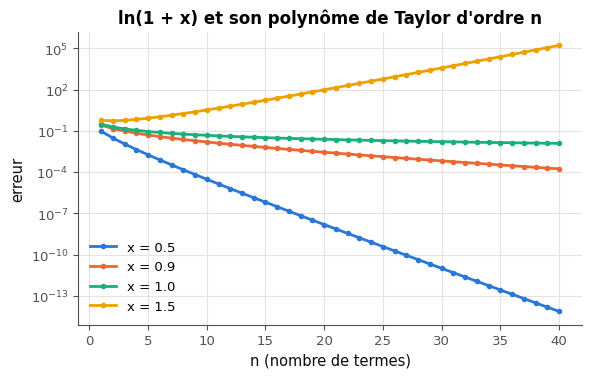

In [36]:
with checked("M05a.25 figure"):
    ns_25 = range(1, 41)
    errors_25 = {x0: [abs(log1p_taylor(x0, n) - math.log1p(x0)) for n in ns_25] for x0 in (0.5, 0.9, 1.0, 1.5)}
    fig, ax = plt.subplots(figsize=(6.5, 3.8))
    for x0, errors in errors_25.items():
        ax.semilogy(ns_25, errors, marker=".", label=f"x = {x0}")
    ax.set(xlabel="n (nombre de termes)", ylabel="erreur", title="ln(1 + x) et son polynôme de Taylor d'ordre n")
    ax.legend()
    plt.show()

💡 Pour $|x| < 1$, l'erreur décroît comme le premier terme négligé, $\frac{|x|^{n+1}}{n+1}$ (une série alternée dont les termes décroissent : l'erreur est plus petite que le premier terme négligé) : 15 termes de plus gagnent 5 décimales en 0,5, mais il en faut 28 en 0,9. En $x = 1$, l'erreur ne décroît que comme $\frac{1}{n + 1}$ : $0{,}005$ pour 100 termes, et il faudrait un million de termes pour $10^{-6}$. En $x = 1{,}5$, le terme $\frac{1{,}5^k}{k}$ grandit sans limite : chaque terme ajouté éloigne davantage la somme, qui oscille de plus en plus fort (97,7 pour 20 termes).

### Ex M05a.26 — Une fonction et ses polynômes de Taylor d'ordre 1, 2 et 3 🎨 ★ ⏱️ 20 min
**Objectif :** tracer une fonction et ses polynômes de Taylor en un point, et voir l'approximation s'améliorer près du point et se dégrader loin de lui.  
**Prérequis :** fiche §3 ; Ex M05a.18 ; R0 (matplotlib) · **Parcours :** C, E

Écris `draw_taylor(ax, f, derivatives, a, orders)`, qui dessine dans l'axe `ax`, sur une grille d'au moins 200 points de $[a - 2, a + 2]$ :
- la fonction `f` (une fonction qui accepte un array, comme `np.sin`) ;
- pour chaque ordre $n$ de `orders`, le polynôme de Taylor d'ordre $n$ en `a`, construit avec les $n + 1$ premières valeurs de `derivatives` ($[f(a), f'(a), \ldots]$) ;
- le point de contact $(a, f(a))$, marqué par un point ;

chaque courbe avec un label, puis la légende. Ta fonction `mymath.approx.taylor_polynomial` donne la valeur d'un polynôme en un point (une compréhension de liste la calcule sur toute la grille), ou bien une somme de termes sur un array.

Puis trace $\sin$ et ses polynômes d'ordre 1, 2 et 3 en $a = \frac{\pi}{4}$, dont les dérivées valent $\frac{\sqrt{2}}{2}, \frac{\sqrt{2}}{2}, -\frac{\sqrt{2}}{2}, -\frac{\sqrt{2}}{2}$.

Dans ta copie : sur quelle largeur autour de $\frac{\pi}{4}$ chaque polynôme reste-t-il proche de la courbe, à l'œil ? Le polynôme d'ordre 2 est-il au-dessus ou au-dessous de la courbe, et pourquoi (signe de $f''$, §1) ? Pourquoi chaque ordre de plus améliore-t-il l'approximation près de $a$ et pas forcément loin de $a$ ?

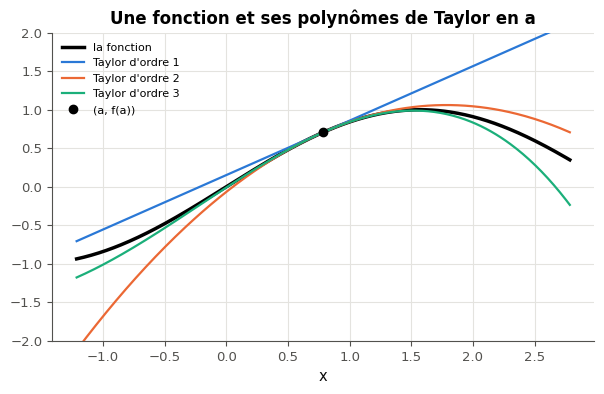

In [37]:
def draw_taylor(ax, f, derivatives, a, orders):
    """In ax, on [a - 2, a + 2]: f, its Taylor polynomials at a of the given orders (from derivatives = [f(a), f'(a),
    ...]) and the point (a, f(a)), each with a label; then the legend."""
    xs = np.linspace(a - 2, a + 2, 401)
    ax.plot(xs, f(xs), color="black", linewidth=2.5, label="la fonction")
    for order in orders:
        values = [mymath.approx.taylor_polynomial(derivatives[:order + 1], a, x) for x in xs]
        ax.plot(xs, values, linewidth=1.6, label=f"Taylor d'ordre {order}")
    ax.plot(a, f(a), "o", color="black", label="(a, f(a))")
    ax.set(xlabel="x", ylim=(-2, 2), title="Une fonction et ses polynômes de Taylor en a")
    ax.legend(fontsize=8)


fig, ax = plt.subplots(figsize=(7, 4))
root_half = math.sqrt(2) / 2
draw_taylor(ax, np.sin, [root_half, root_half, -root_half, -root_half], math.pi / 4, (1, 2, 3))
plt.show()

**Vérifications automatiques** (sur un autre exemple ; la figure elle-même se juge à l'œil).

In [38]:
with checked("M05a.26 vérifications"):
    problems = []
    a_t = 0.5                                                          # another example: exp at 0.5, orders 1 and 3
    ders_t = [math.exp(a_t)] * 4

    def poly_t(order, xs):
        return sum(ders_t[k] * (xs - a_t) ** k / math.factorial(k) for k in range(order + 1))

    expected = {"la fonction": np.exp, "le polynôme d'ordre 1": lambda xs: poly_t(1, xs),
                "le polynôme d'ordre 3": lambda xs: poly_t(3, xs)}
    fig, ax = plt.subplots(figsize=(6, 4))
    try:
        created = drawn(draw_taylor, ax, np.exp, ders_t, a_t, (1, 3))
    finally:
        plt.close(fig)                                                 # only the checks below are shown here
    if created:
        problems.append("draw_taylor ouvre sa propre figure : dessine dans l'axe reçu")
    else:
        curves = []
        for line in ax.get_lines():
            xs = np.asarray(line.get_xdata(), dtype=float)
            ys = np.asarray(line.get_ydata(), dtype=float)
            if xs.size >= 50:
                curves.append((line, xs, ys))
        for name, function in expected.items():
            match = [line for line, xs, ys in curves if np.allclose(ys, function(xs), rtol=1e-6, atol=1e-9)]
            if not match:
                problems.append(f"aucune courbe d'au moins 50 points n'est {name}" + (
                    "" if name == "la fonction" else " (le terme d'ordre k est f⁽ᵏ⁾(a) (x − a)^k / k!, pour k de 0 "
                                                     "à l'ordre)"))
            elif not match[0].get_label() or match[0].get_label().startswith("_"):
                problems.append(f"{name} : donne-lui un label, pour la légende")
        if curves and max(xs.max() - xs.min() for _, xs, _ in curves) < 3.9:
            problems.append("trace les courbes sur tout l'intervalle [a − 2, a + 2]")
        marked = any(np.any(np.isclose(np.asarray(line.get_xdata(), dtype=float), a_t))
                     and np.any(np.isclose(np.asarray(line.get_ydata(), dtype=float), math.exp(a_t)))
                     and len(line.get_xdata()) < 5 for line in ax.get_lines())
        marked = marked or any(np.any(np.all(np.isclose(c.get_offsets(), [a_t, math.exp(a_t)]), axis=1))
                               for c in ax.collections if len(c.get_offsets()))
        if not marked:
            problems.append("marque le point (a, f(a)) par un point, par exemple ax.plot(a, f(a), \"o\")")
        if ax.get_legend() is None:
            problems.append("il manque la légende (ax.legend())")
    if problems:
        print("❌ Ex M05a.26 : à revoir : " + " ; ".join(problems) + ".")
    else:
        print("✅ Ex M05a.26 : la fonction, ses polynômes de Taylor et le point de contact sont justes, avec une "
              "légende.")

✅ Ex M05a.26 : la fonction, ses polynômes de Taylor et le point de contact sont justes, avec une légende.


💡 Près de $\frac{\pi}{4}$, les trois polynômes collent à la courbe, et chaque ordre de plus élargit la zone où l'écart reste invisible (environ $\pm 0{,}3$, $\pm 0{,}6$ et $\pm 1$ à l'œil). Le polynôme d'ordre 2 est au-dessus de la courbe juste à gauche de $\frac{\pi}{4}$ et au-dessous juste à droite : l'erreur commence par le terme $-\frac{\sqrt{2}}{12}(x - a)^3$, qui change de signe en $a$. Loin de $a$, chaque polynôme part vers l'infini (un polynôme non constant n'est pas borné), alors que $\sin$ reste entre $-1$ et 1 : Taylor est une approximation **locale**.

## Partie C · Erreurs classiques, savoir-faire et défi

Fiche §4, §6 et §8. Quatre erreurs d'une softmax à trouver, la tolérance d'un test de flottants, puis une racine cubique en quelques pas.

### Ex M05a.27 — Chasse à l'erreur : une softmax qui renvoie `nan` 🐛 ★ ⏱️ 15 min
**Objectif :** repérer dans du code les erreurs classiques d'une softmax et d'un log-sum-exp, de formule ou de calcul en flottants, puis calculer les bonnes valeurs.  
**Prérequis :** fiche §6 et §8 ; Ex M05a.10 · **Parcours :** C

Un modèle donne trois scores $\mathbf{v} = (1000,\ 999,\ 200)$. Une collègue a écrit six lignes, chacune avec un commentaire qui dit ce qu'elle veut calculer ; chaque ligne utilise les variables des lignes précédentes telles qu'elles **devraient** être (on suppose les lignes précédentes justes). Quatre lignes ne calculent pas ce que dit leur commentaire : une erreur de formule, ou un calcul qui échoue en `float64`. **Sans exécuter de code**, trouve-les.

```python
v = [1000.0, 999.0, 200.0]
m = min(v)                                        # (A) the largest score
total = sum(math.exp(x - m) for x in v)           # (B) Σ exp(v_i − m), with m the largest score
lse = math.log(total)                             # (C) log-sum-exp of v
p1 = math.exp(v[0] - m) / total                   # (D) softmax(v)[0]
log_p3 = math.log(math.exp(v[2] - m) / total)     # (E) log-softmax of the third score
s = sum(math.exp(x - m) for x in v) / len(v)      # (F) the sum of the three probabilities of softmax(v)
```

Questions :
- a) les lettres des lignes fausses, dans l'ordre alphabétique (un texte) ;
- b) pour chacune des six lignes, de (A) à (F), la bonne valeur de ce que dit son commentaire (une liste de 6 nombres, 3 décimales).

Dans ta copie : pour chaque ligne fausse, quelle erreur a été faite, et comment la corriger ? Laquelle donne une erreur à l'exécution plutôt qu'une valeur fausse ? D'où vient le `nan` du titre, quand la ligne (A) est fausse (calcule `math.exp(1000 - 200)` en NumPy, puis `inf / inf`) ?

In [39]:
answer_M05a_27a = "ACEF"
v = [1000.0, 999.0, 200.0]
m = max(v)                                              # (A) the largest score
total = sum(math.exp(x - m) for x in v)                 # (B) correct
lse = m + math.log(total)                               # (C) add m back
p1 = math.exp(v[0] - m) / total                         # (D) correct
log_p3 = v[2] - lse                                     # (E) exp(-800) underflows to 0: use v_i − LSE
s = sum(math.exp(x - m) / total for x in v)             # (F) divide by the total, not by n
answer_M05a_27b = [m, total, lse, p1, log_p3, s]
print(answer_M05a_27a, [round(value, 4) for value in answer_M05a_27b])
with np.errstate(over="ignore"):                       # NumPy warns of the overflow; the warning is hidden here
    print("exp(-800):", math.exp(-800), "· in NumPy, exp(800):", np.exp(np.float64(800)))

ACEF [1000.0, 1.3679, 1000.3133, 0.7311, -800.3133, 1.0]
exp(-800): 0.0 · in NumPy, exp(800): inf


In [40]:
wbm.record("M05a.27a", "ACEF",
           mistakes={"il manque une ligne fautive : vérifie quel score chaque ligne retire avant de prendre l'exponentielle": "CEF",
                     "il manque une ligne fautive : vérifie que chaque log-sum-exp revient à l'échelle des scores": "AEF",
                     "il manque une ligne fautive : vérifie que chaque calcul reste représentable en float64 à chaque étape": "ACF",
                     "il manque une ligne fautive : vérifie ce que somme chaque ligne, et par quoi elle divise": "ACE",
                     "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple": {"ABCEF", "ACDEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie quel score chaque ligne retire avant de prendre l'exponentielle": {"BCEF", "CDEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie que chaque log-sum-exp revient à l'échelle des scores": {"ABEF", "ADEF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie que chaque calcul reste représentable en float64 à chaque étape": {"ABCF", "ACDF"},
                     "une des lignes que tu cites est correcte, et il manque une ligne fautive : vérifie ce que somme chaque ligne, et par quoi elle divise": {"ABCE", "ACDE"},
                     "plusieurs lignes fautives manquent : reprends chaque ligne avec un petit exemple": {"A", "C", "E", "F", "AC", "AE", "AF", "CE", "CF", "EF"},
                     "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple": {"B", "D", "AB", "AD", "BC", "BD", "BE", "BF", "CD", "DE", "DF", "ABC", "ABD", "ABE", "ABF", "ACD", "ADE", "ADF", "BCD", "BCE", "BCF", "BDE", "BDF", "BEF", "CDE", "CDF", "DEF", "ABCD", "ABDE", "ABDF", "BCDE", "BCDF", "BDEF", "ABCDE", "ABCDF", "ABDEF", "BCDEF"},
                     "plusieurs lignes que tu cites sont correctes : vérifie chacune avec un petit exemple": {"ABCDEF"}})
wbm.record("M05a.27b", [1000, 1.3678794412, 1000.3132616875, 0.7310585786, -800.3132616875, 1.0], decimals=3,
           mistakes={"(C) : le log-sum-exp de v rajoute le maximum m": [1000, 1.3678794412, 0.3132616875,
                                                                        0.7310585786, -800.3132616875, 1.0],
                     "(E) : le log-softmax est v₃ − LSE(v), et LSE(v) n'est pas le seul maximum":
                         [1000, 1.3678794412, 1000.3132616875, 0.7310585786, -800.0, 1.0]})

WBM_ANSWER {"hash": "b0020a7efe219c27dcf8cdac9f15479d243044ada729d4bd832782f3be42463b", "id": "M05a.27a", "kind": "str", "mistakes": {"027c2fe9a2f4d835b8b6db06df3a241738be187472a9b7c42cb91a431279b05e": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "08f0edae817e7c5d63da9b479a8e236fda284830819388ceebcc3e290d90e08c": "une ligne de trop : une des lignes que tu cites est correcte ; refais le calcul de chacune sur un petit exemple", "0900c56004d37291e3f469d2f048b989464e5bc578cfe8e90e2a0c131233c692": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0a0271887206f9f2a0ee3cad67173657b262ec11a28c6e361c6968c4eee3608c": "il manque des lignes fautives, et des lignes que tu cites sont correctes : reprends chaque ligne avec un petit exemple", "0cd94104436d165c9543639dfdb02c1faef1d8f424b5ce28dd4df092f3c73944": "il manque des lignes fautives, et des lignes

💡 (A) Il faut retirer le **maximum** : avec le minimum, `math.exp(1000 - 200)` lève une `OverflowError` (en NumPy, il donne `inf`, puis `inf / inf` donne `nan`). (C) Le log-sum-exp est $m + \ln(\text{total})$, environ 1 000,313. (E) La formule est juste sur le papier, mais $e^{-800}$ s'efface en `float64` (il est plus petit que $5 \times 10^{-324}$) : la ligne calcule `math.log(0.0)` et lève une `ValueError`. Le log-softmax se calcule directement, $v_3 - \text{LSE}(\mathbf{v}) \approx -800{,}313$ (M05a.14). (F) La somme des probabilités divise chaque exponentielle par le total, pas par $n$ : elle vaut 1. Les lignes (B) et (D) sont justes.

### Ex M05a.28 — Erreur relative ou absolue : choisir la tolérance d'un test 🛠️ ★ ⏱️ 10 min
**Objectif :** écrire la comparaison de deux flottants qu'utilisent les tests, avec une tolérance relative et une tolérance absolue, et savoir laquelle choisir.  
**Prérequis :** fiche §6 · **Parcours :** C

On ne compare jamais deux flottants calculés avec `==` : `0.1 + 0.2 == 0.3` est faux (R0). On vérifie qu'ils sont **proches**. Mais proches comment ?
- Une tolérance **absolue**, $|a - b| \le 10^{-9}$, est absurde pour des nombres de l'ordre de $10^{20}$, où deux flottants voisins sont déjà distants de plus de 10 000 (§6).
- Une tolérance **relative**, $|a - b| \le 10^{-9}\,\max(|a|, |b|)$, est absurde près de 0 : un résultat qui devrait valoir 0 et vaut $10^{-17}$ (une annulation, §6) n'est « proche » d'aucun nombre.

Les bibliothèques combinent donc les deux. Écris `close_enough(got, expected, rel_tol=1e-9, abs_tol=0.0)`, qui renvoie `True` si et seulement si

$$|\text{got} - \text{expected}| \le \max\big(\text{rel\_tol} \times \max(|\text{got}|, |\text{expected}|),\ \text{abs\_tol}\big),$$

avec trois règles : deux valeurs égales (même infinies) sont proches ; `nan` n'est proche de rien, pas même de lui-même ; une infinie n'est proche que d'elle-même. Une tolérance négative lève une `ValueError`. C'est la définition de `math.isclose`, qui est donc interdite ici : la vérification compare tes réponses aux siennes, sur des cas choisis.

Dans ta copie : quelle tolérance choisirais-tu pour tester que `logsumexp([1000, 1000])` vaut $1000 + \ln 2$ ? Pour tester qu'une erreur d'arrondi, qui devrait être nulle, est négligeable ? `numpy.isclose(a, b)` utilise $|a - b| \le \text{atol} + \text{rtol}\,|b|$, avec par défaut `atol=1e-8` : pourquoi n'est-elle pas symétrique, et quel piège cache son `atol` pour de très petits nombres ?

In [41]:
def close_enough(got, expected, rel_tol=1e-9, abs_tol=0.0):
    """True when |got - expected| <= max(rel_tol * max(|got|, |expected|), abs_tol), like math.isclose (without
    using it). ValueError for a negative tolerance."""
    if rel_tol < 0 or abs_tol < 0:
        raise ValueError("the tolerances must be non-negative")
    if got == expected:                       # exact equality, infinities included
        return True
    if math.isinf(got) or math.isinf(expected) or math.isnan(got) or math.isnan(expected):
        return False                          # an infinity is close only to itself; nan to nothing
    return abs(got - expected) <= max(rel_tol * max(abs(got), abs(expected)), abs_tol)


print(close_enough(1e20, 1e20 + 1e5), close_enough(0.0, 1e-17), close_enough(0.0, 1e-17, abs_tol=1e-12))

True False True


In [42]:
with checked("M05a.28 vérifications"):
    problems = []
    cases = [((1.0, 1.0 + 1e-10), {}), ((1e20, 1e20 + 1e5), {}), ((1e-20, 2e-20), {}), ((0.0, 1e-12), {}),
             ((0.0, 1e-12), {"abs_tol": 1e-9}), ((100.0, 101.0), {"rel_tol": 0.01}),
             ((100.0, 102.0), {"rel_tol": 0.01}), ((1.0, 1.1), {"rel_tol": 0.091}), ((1.1, 1.0), {"rel_tol": 0.091}),
             ((5.0, 5.0), {"rel_tol": 0.0}), ((math.inf, math.inf), {}), ((math.inf, 1e308), {"rel_tol": 0.5}),
             ((math.nan, math.nan), {}), ((-3.0, 3.0), {"rel_tol": 2.5})]
    for (got, expected), options in cases:
        reference = math.isclose(got, expected, **options)
        call = f"close_enough({got!r}, {expected!r}" + "".join(f", {k}={v!r}" for k, v in options.items()) + ")"
        try:
            answer = close_enough(got, expected, **options)
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"{call} lève {type(exc).__name__} ({exc}) ; attendu {reference}")
            continue
        if answer is not reference:
            problems.append(f"{call} : attendu {reference}, obtenu {answer!r}")
    for options in ({"rel_tol": -1e-9}, {"abs_tol": -1.0}):
        try:
            close_enough(1.0, 1.0, **options)
        except ValueError:
            pass
        except NotImplementedError:
            raise
        except Exception as exc:  # noqa: BLE001
            problems.append(f"une tolérance négative ({options}) lève {type(exc).__name__} : attendu une ValueError")
        else:
            problems.append(f"une tolérance négative ({options}) est acceptée : attendu une ValueError")
    if problems:
        print("❌ Ex M05a.28 : à revoir : " + " ; ".join(problems[:5]) + ("…" if len(problems) > 5 else "."))
    else:
        print("✅ Ex M05a.28 : close_enough donne les mêmes réponses que math.isclose, cas limites compris.")

✅ Ex M05a.28 : close_enough donne les mêmes réponses que math.isclose, cas limites compris.


💡 Pour `logsumexp([1000, 1000])`, une tolérance relative (par exemple $10^{-12}$) : le résultat est de l'ordre de 1 000, et l'erreur d'arrondi lui est proportionnelle. Pour une valeur qui devrait être nulle, il faut une tolérance absolue, choisie selon l'échelle des nombres qui l'ont produite (par exemple $10^{-12}$ si l'on a soustrait des nombres de l'ordre de 1). `numpy.isclose(a, b)` multiplie `rtol` par $|b|$ seulement : `isclose(a, b)` et `isclose(b, a)` peuvent différer ; et son `atol=1e-8` par défaut déclare « proches » $10^{-10}$ et $10^{-20}$, deux nombres que rien ne rapproche : pour de petites grandeurs, il faut le baisser.

### Ex M05a.29 — Défi : une racine cubique à 10⁻¹² en le moins d'itérations possible 🏆 ★★★ ⏱️ 25 min
**Objectif :** programmer une racine cubique par la méthode de Newton, avec un point de départ assez bon pour converger en quelques pas, quelle que soit la taille du nombre.  
**Prérequis :** fiche §4 et §6 ; Ex M05a.12 et M05a.19 · **Parcours :** C

Écris `cube_root(a)`, qui renvoie le couple `(x, steps)` : une approximation de $\sqrt[3]{a}$ pour $a > 0$, obtenue par la méthode de Newton sur $f(x) = x^3 - a$, et le nombre de pas de Newton effectués. Un pas s'écrit $x \leftarrow x - \frac{x^3 - a}{3x^2} = \frac{1}{3}\big(2x + \frac{a}{x^2}\big)$. Arrête-toi quand deux valeurs successives sont presque égales (par exemple $|x_{k+1} - x_k| \le 10^{-15}\,x_{k+1}$).

**L'objectif** : une erreur relative inférieure à $10^{-12}$ en **6 pas au plus**, pour des nombres de $10^{-300}$ à $10^{300}$. Tout se joue au point de départ : la convergence quadratique (M05a.12) n'opère que près de la racine, et partir de $x_0 = a$ ou de $x_0 = 1$ coûte plus de cent pas pour $a = 10^{30}$. Une piste : `m, e = math.frexp(a)` écrit $a = m \times 2^e$ avec $0{,}5 \le m < 1$ ; avec $e = 3q + r$ (`divmod(e, 3)`), $\sqrt[3]{a} = \sqrt[3]{m \times 2^r} \times 2^q$, et il ne reste qu'à approcher $\sqrt[3]{y}$ pour $y = m \times 2^r$ entre 0,5 et 4, par exemple par une droite.

La vérification calcule ta racine pour onze nombres, de $5 \times 10^{-300}$ à $10^{300}$, affiche la pire erreur relative et le pire nombre de pas, puis vérifie `cube_root(50.0)[0]` (10 décimales).

Dans ta copie : l'erreur relative de ton point de départ, au pire ? Combien de pas faut-il alors, d'après $\varepsilon_{k+1} \approx \varepsilon_k^2$ (pour $x^3 - a$, l'erreur relative est à peu près élevée au carré à chaque pas) ? Pourquoi, depuis $x_0 = 1$ et pour $a = 10^{30}$, la suite ne fait-elle que se multiplier par environ $\frac{2}{3}$ pendant des dizaines de pas ?

In [43]:
ROOTS_OF_2 = (1.0, 2 ** (1 / 3), 2 ** (2 / 3))           # cube roots of 2**r for r = 0, 1, 2


def cube_root(a):
    """The cube root of a > 0 by Newton's method on x**3 - a, and the number of Newton steps taken: (x, steps)."""
    if not a > 0:
        raise ValueError(f"a must be positive, got {a!r}")
    m, e = math.frexp(a)                       # a = m × 2**e with 0.5 <= m < 1
    q, r = divmod(e, 3)                        # 2**e = 2**(3q) × 2**r
    x = (0.6 + 0.4 * m) * ROOTS_OF_2[r] * 2.0 ** q    # 0.6 + 0.4 m is within 1 % of the cube root of m
    for steps in range(1, 51):
        x_new = (2 * x + a / (x * x)) / 3
        if abs(x_new - x) <= 1e-15 * x_new:
            return x_new, steps
        x = x_new
    raise RuntimeError("no convergence after 50 steps")


def steps_from(a, x):
    """The number of Newton steps from the starting point x (the naive start)."""
    for steps in range(1, 1001):
        x_new = (2 * x + a / (x * x)) / 3
        if abs(x_new - x) <= 1e-15 * x_new:
            return steps
        x = x_new


print("cube_root(50):", cube_root(50.0), "· 50 ** (1/3):", 50 ** (1 / 3))
print("steps from x0 = 1 for a = 1e30:", steps_from(1e30, 1.0), "· with the good start:", cube_root(1e30)[1])

cube_root(50): (3.684031498640387, 4) · 50 ** (1/3): 3.6840314986403864
steps from x0 = 1 for a = 1e30: 118 · with the good start: 4


In [44]:
wbm.record("M05a.29", 3.6840314986, decimals=10)

WBM_ANSWER {"coarse_any": {"0": ["bb945bbe20a30e805dbe7682c8e6e34c218029469364d6a1f8827f6f8ab074c3"]}, "coarser": {"1": ["181d94184c9a39f93e9f9660bc451ec1204433fe3b7fc8c2027996a1acf664cd"], "2": ["5319c557ef8a654d9bd4fd341667c140e4ab6273d739238691fc44c3a67900a4"], "3": ["47b0e0701f71d28653d22a40d5dd56764a67e48d29a8d712b9be3d2de41201be"], "4": ["e5f9b328bb3a1fcfaecf1e8a99a20588fcfb4a48eb4c333413e2f116ae28f060"], "5": ["da412554ce3d34d08a0ec6dc402ac13b239a5eaa0984217bbfb5dfadfaeeeb7c"], "6": ["5d9ae798fec2f00c87b8c7d447558f92843f1ababb37e604fd069d74866c0e10"], "7": ["c8e3a243333f3151efd2d5097039c65184a954e46fc02c21ee23d331d4a7c445"], "8": ["27aec3d41eac316d140f9d2facac8e9264df02e2f58b7c41d0900bd31d3e2c45"]}, "decimals": 10, "hash": "9b1904744baaa6c1133ed2b9bfa8dff1585bff894a36e333ce1bac7101fb0129", "hash_coarse": "60fb8b65217c8be954675387e723705df78a6a574f99944a5567de0796d71eb2", "id": "M05a.29", "kind": "float", "magnitude": 0, "sign": 1}
📝 Ex M05a.29 : réponse enregistrée (float, 10 dé

In [45]:
CASES_29 = [50.0, 2.0, 0.008, 1e-30, 3.7e25, 123456.789, 1e300, 5e-300, 0.9999, 7.0e-5, 1.0]
with checked("M05a.29 défi"):
    worst_error, worst_steps = 0.0, 0
    for a in CASES_29:
        root, steps = cube_root(a)
        exact = a ** (1 / 3)
        worst_error = max(worst_error, abs(root - exact) / exact)
        worst_steps = max(worst_steps, steps)
    print(f"Pire erreur relative : {worst_error:.1e} · pire nombre d'itérations : {worst_steps}")
    if not worst_error < 1e-12:
        print("❌ Ex M05a.29 : la précision n'est pas atteinte (objectif : erreur relative < 1e-12) : continue les pas "
              "de Newton jusqu'à ce que deux valeurs successives soient presque égales.")
    elif worst_steps > 6:
        print("❌ Ex M05a.29 : précision atteinte, mais trop d'itérations (objectif : 6 au plus) : soigne le point de "
              "départ (math.frexp).")
    else:
        print("✅ Ex M05a.29 : défi réussi, une précision de 1e-12 en 6 itérations au plus, de 1e-300 à 1e300.")

Pire erreur relative : 1.3e-14 · pire nombre d'itérations : 4
✅ Ex M05a.29 : défi réussi, une précision de 1e-12 en 6 itérations au plus, de 1e-300 à 1e300.


💡 Avec $x_0 = (0{,}6 + 0{,}4\,m) \times 2^{r/3} \times 2^q$, l'erreur relative de départ reste sous 1 % ($0{,}6 + 0{,}4\,m$ approche $\sqrt[3]{m}$ à 0,9 % près sur $[0{,}5 ;\ 1[$). Les pas donnent alors environ $10^{-4}$, $10^{-8}$, $10^{-16}$ : trois pas suffisent, plus un quatrième qui constate que la valeur ne bouge plus. Depuis $x_0 = 1$ pour $a = 10^{30}$, il faut 118 pas : tant que $x^3 \gg a$, le pas vaut à peu près $x \leftarrow \frac{2x}{3}$, une décroissance géométrique lente, et la convergence quadratique ne commence qu'une fois arrivé près de $10^{10}$.

## ✅ Bilan

**Auto-évaluation** (note-toi de 0 à 3 dans `mon_travail/suivi/auto_evaluation.md`) :
1. Sais-tu étudier la convexité d'une fonction et trouver ses extrema globaux sur un intervalle ?
2. Sais-tu écrire un polynôme de Taylor, borner son erreur, et dire à quel ordre une différence finie approche une dérivée ?
3. Sais-tu utiliser la méthode de Newton, et dire quand elle converge vite ?
4. Sais-tu ce qu'un `float64` représente exactement, et calculer un log-sum-exp ou une softmax sans overflow ?

**La suite** : le chapitre 5 de workbookIA (dérivées, différences finies, gradient), puis M05b, les fonctions de plusieurs variables et le gradient.